# Q1 Q4

In [ ]:

# ============================================================
# Q1 - CELL 1: LIBRARIES, DATASET AND PREPROCESSING
# ============================================================

import os
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

# Reproducibility
MASTER_SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(MASTER_SEED)

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 55)
print("ENVIRONMENT INFORMATION")
print("=" * 55)
print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Using CPU.")

# ------------------------------------------------------------
# LOAD DATASET
# ------------------------------------------------------------

dataset = load_breast_cancer()

X = dataset.data.astype(np.float32)
y = dataset.target.astype(np.float32)

print("\n" + "=" * 55)
print("DATASET INFORMATION")
print("=" * 55)

print("Dataset name: Wisconsin Breast Cancer Diagnostic")
print("Total samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))
print("Class names:", dataset.target_names)

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

# ------------------------------------------------------------
# STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ------------------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=MASTER_SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=MASTER_SEED,
    stratify=y_temp
)

# Standardisation: fit ONLY on training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# Dataset split table
split_table = pd.DataFrame({
    "Subset": ["Training", "Validation", "Testing"],
    "Samples": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Percentage": [
        len(X_train) / len(X) * 100,
        len(X_val) / len(X) * 100,
        len(X_test) / len(X) * 100
    ]
})

print("\nDATA SPLIT")
display(split_table.round(2))

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

# Convert datasets into PyTorch tensors
X_train_tensor = torch.tensor(X_train)
y_train_tensor = torch.tensor(y_train).reshape(-1, 1)

X_val_tensor = torch.tensor(X_val)
y_val_tensor = torch.tensor(y_val).reshape(-1, 1)

X_test_tensor = torch.tensor(X_test)
y_test_tensor = torch.tensor(y_test).reshape(-1, 1)

print("\nDataset preparation completed.")


ENVIRONMENT INFORMATION
PyTorch version: 2.14.1+cpu
Device: cpu
GPU unavailable. Using CPU.

DATASET INFORMATION
Dataset name: Wisconsin Breast Cancer Diagnostic
Total samples: 569
Number of features: 30
Number of classes: 2
Class names: ['malignant' 'benign']

Class distribution:
0.0    212
1.0    357
Name: count, dtype: int64

DATA SPLIT


,Subset,Samples,Percentage
0,Training,398,69.95
1,Validation,85,14.94
2,Testing,86,15.11


Training shape: (398, 30)
Validation shape: (85, 30)
Testing shape: (86, 30)

Dataset preparation completed.


In [ ]:

# ============================================================
# Q1 - CELL 2: NETWORK ARCHITECTURE
# ============================================================

class DeepFeedForwardNetwork(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_sizes,
        activation,
        initialization="standard"
    ):

        super().__init__()

        self.activation_name = activation
        self.initialization = initialization

        self.hidden_layers = nn.ModuleList()

        previous_size = input_size

        # Construct hidden layers
        for hidden_size in hidden_sizes:

            self.hidden_layers.append(
                nn.Linear(previous_size, hidden_size)
            )

            previous_size = hidden_size

        # Output layer
        self.output_layer = nn.Linear(previous_size, 1)

        # Activation selection
        if activation == "Sigmoid":
            self.activation = nn.Sigmoid()

        elif activation == "Tanh":
            self.activation = nn.Tanh()

        elif activation == "ReLU":
            self.activation = nn.ReLU()

        else:
            raise ValueError("Unknown activation function")

        # Weight initialisation
        self.initialize_weights()

    def initialize_weights(self):

        for layer in self.hidden_layers:

            if self.initialization == "poor":

                # Deliberately high-variance initialisation
                nn.init.normal_(
                    layer.weight,
                    mean=0.0,
                    std=0.5
                )

            elif self.activation_name == "ReLU":

                nn.init.kaiming_normal_(
                    layer.weight,
                    nonlinearity="relu"
                )

            else:

                nn.init.xavier_uniform_(
                    layer.weight
                )

            nn.init.zeros_(layer.bias)

        # Keep output initialisation consistent
        nn.init.xavier_uniform_(
            self.output_layer.weight
        )
        nn.init.zeros_(self.output_layer.bias)

    def forward(self, x):

        self.hidden_activations = []

        for layer in self.hidden_layers:

            x = layer(x)
            x = self.activation(x)

            # Store activations for ReLU analysis
            self.hidden_activations.append(x)

        logits = self.output_layer(x)

        return logits


# ------------------------------------------------------------
# CONFIGURATIONS
# ------------------------------------------------------------

CONFIGURATIONS = {

    "Shallow": {
        "hidden_sizes": [64, 32],
        "initialization": "standard"
    },

    "Deep": {
        "hidden_sizes": [64] * 8,
        "initialization": "standard"
    },

    "Poor_Initialization": {
        "hidden_sizes": [64] * 8,
        "initialization": "poor"
    }

}

ACTIVATIONS = ["Sigmoid", "Tanh", "ReLU"]

SEEDS = [42, 123, 2026]

print("Network configurations:")

for name, config in CONFIGURATIONS.items():

    print(
        name,
        "| Hidden layers:",
        len(config["hidden_sizes"]),
        "| Neurons:",
        config["hidden_sizes"],
        "| Initialisation:",
        config["initialization"]
    )

print("\nActivations:", ACTIVATIONS)
print("Random seeds:", SEEDS)
print("Total experiments:",
      len(CONFIGURATIONS) * len(ACTIVATIONS) * len(SEEDS))


Network configurations:
Shallow | Hidden layers: 2 | Neurons: [64, 32] | Initialisation: standard
Deep | Hidden layers: 8 | Neurons: [64, 64, 64, 64, 64, 64, 64, 64] | Initialisation: standard
Poor_Initialization | Hidden layers: 8 | Neurons: [64, 64, 64, 64, 64, 64, 64, 64] | Initialisation: poor

Activations: ['Sigmoid', 'Tanh', 'ReLU']
Random seeds: [42, 123, 2026]
Total experiments: 27


In [ ]:

# ============================================================
# Q1 - CELL 3: TRAINING AND EXPERIMENTAL MEASUREMENTS
# ============================================================

BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 0.001

performance_records = []
gradient_records = []
history_records = []
relu_records = []

experiment_start = time.time()

# ------------------------------------------------------------
# HELPER FUNCTION: CREATE DATALOADER
# ------------------------------------------------------------

def create_train_loader(seed):

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )


val_loader = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=BATCH_SIZE,
    shuffle=False
)

train_eval_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ------------------------------------------------------------
# HELPER FUNCTION: LOSS AND PREDICTIONS
# ------------------------------------------------------------

criterion = nn.BCEWithLogitsLoss()


def evaluate_model(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    predictions = []
    actual_values = []

    with torch.no_grad():

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)

            loss = criterion(logits, yb)

            total_loss += loss.item() * len(xb)
            total_samples += len(xb)

            predicted = (
                torch.sigmoid(logits) >= 0.5
            ).int()

            predictions.extend(
                predicted.cpu().numpy().flatten()
            )

            actual_values.extend(
                yb.cpu().numpy().flatten()
            )

    average_loss = total_loss / total_samples

    accuracy = accuracy_score(
        actual_values, predictions
    )

    precision = precision_score(
        actual_values,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        actual_values,
        predictions,
        zero_division=0
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "predictions": predictions,
        "actual": actual_values
    }


# ------------------------------------------------------------
# MAIN EXPERIMENT LOOP
# ------------------------------------------------------------

for config_name, config in CONFIGURATIONS.items():

    for activation in ACTIVATIONS:

        for seed in SEEDS:

            print("\n" + "-" * 65)

            print(
                "Configuration:", config_name,
                "| Activation:", activation,
                "| Seed:", seed
            )

            set_seed(seed)

            train_loader = create_train_loader(seed)

            model = DeepFeedForwardNetwork(
                input_size=30,
                hidden_sizes=config["hidden_sizes"],
                activation=activation,
                initialization=config["initialization"]
            ).to(device)

            optimizer = torch.optim.Adam(
                model.parameters(),
                lr=LEARNING_RATE
            )

            # Store gradient norms for first epoch
            epoch_gradient_norms = {
                i: [] for i in range(
                    len(config["hidden_sizes"])
                )
            }

            # Training history
            training_history = []

            # ------------------------------------------------
            # EPOCH LOOP
            # ------------------------------------------------

            for epoch in range(EPOCHS):

                model.train()

                epoch_loss = 0.0
                sample_count = 0

                for xb, yb in train_loader:

                    xb = xb.to(device)
                    yb = yb.to(device)

                    optimizer.zero_grad()

                    logits = model(xb)

                    loss = criterion(logits, yb)

                    loss.backward()

                    # Record layer-wise gradient norms
                    # across every batch of the first epoch
                    if epoch == 0:

                        for layer_idx, layer in enumerate(
                            model.hidden_layers
                        ):

                            gradient_norm = (
                                layer.weight.grad.norm().item()
                            )

                            epoch_gradient_norms[
                                layer_idx
                            ].append(gradient_norm)

                    optimizer.step()

                    epoch_loss += loss.item() * len(xb)
                    sample_count += len(xb)

                average_train_loss = (
                    epoch_loss / sample_count
                )

                val_metrics = evaluate_model(
                    model, val_loader
                )

                training_history.append({
                    "Configuration": config_name,
                    "Activation": activation,
                    "Seed": seed,
                    "Epoch": epoch + 1,
                    "Train_Loss": average_train_loss,
                    "Validation_Loss": val_metrics["loss"]
                })

                if (epoch + 1) % 5 == 0:

                    print(
                        f"Epoch {epoch+1:02d}/{EPOCHS} | "
                        f"Train Loss: {average_train_loss:.5f} | "
                        f"Val Loss: {val_metrics['loss']:.5f}"
                    )

            # ------------------------------------------------
            # GRADIENT RESULTS
            # ------------------------------------------------

            for layer_idx, values in epoch_gradient_norms.items():

                gradient_records.append({

                    "Configuration": config_name,
                    "Activation": activation,
                    "Seed": seed,
                    "Layer": layer_idx + 1,

                    "Gradient_Norm": np.mean(values),

                    "Gradient_Std": np.std(values)

                })

            # ------------------------------------------------
            # FINAL TRAINING AND VALIDATION METRICS
            # ------------------------------------------------

            train_metrics = evaluate_model(
                model, train_eval_loader
            )

            val_metrics = evaluate_model(
                model, val_loader
            )

            test_metrics = evaluate_model(
                model, test_loader
            )

            # ------------------------------------------------
            # RELU INACTIVITY ANALYSIS
            # ------------------------------------------------

            if activation == "ReLU":

                model.eval()

                all_activations = [
                    [] for _ in model.hidden_layers
                ]

                with torch.no_grad():

                    for xb, _ in train_eval_loader:

                        xb = xb.to(device)

                        model(xb)

                        for layer_idx, activation_values in enumerate(
                            model.hidden_activations
                        ):

                            all_activations[layer_idx].append(
                                activation_values.cpu()
                            )

                for layer_idx, batches in enumerate(
                    all_activations
                ):

                    activations_full = torch.cat(
                        batches, dim=0
                    )

                    inactive_fraction = (
                        activations_full == 0
                    ).float().mean().item()

                    # A neuron is classified as dead if it
                    # produces zero output for every training sample
                    dead_neuron_fraction = (
                        (activations_full == 0).all(dim=0)
                    ).float().mean().item()

                    relu_records.append({

                        "Configuration": config_name,
                        "Seed": seed,
                        "Layer": layer_idx + 1,

                        "Inactive_Activation_Fraction":
                            inactive_fraction,

                        "Dead_Neuron_Fraction":
                            dead_neuron_fraction

                    })

            # ------------------------------------------------
            # SAVE PERFORMANCE RESULTS
            # ------------------------------------------------

            performance_records.append({

                "Configuration": config_name,
                "Activation": activation,
                "Seed": seed,

                "Train_Loss": train_metrics["loss"],
                "Validation_Loss": val_metrics["loss"],

                "Train_Accuracy": train_metrics["accuracy"],
                "Validation_Accuracy": val_metrics["accuracy"],

                "Validation_Precision": val_metrics["precision"],
                "Validation_Recall": val_metrics["recall"],

                "Test_Loss": test_metrics["loss"],
                "Test_Accuracy": test_metrics["accuracy"],
                "Test_Precision": test_metrics["precision"],
                "Test_Recall": test_metrics["recall"]

            })

            history_records.extend(training_history)

            print(
                "Final Validation Accuracy:",
                round(val_metrics["accuracy"], 4)
            )

            print(
                "Final Test Accuracy:",
                round(test_metrics["accuracy"], 4)
            )


# ------------------------------------------------------------
# CONVERT RESULTS TO DATAFRAMES
# ------------------------------------------------------------

performance_df = pd.DataFrame(performance_records)

gradient_df = pd.DataFrame(gradient_records)

history_df = pd.DataFrame(history_records)

relu_df = pd.DataFrame(relu_records)

print("\n" + "=" * 65)
print("ALL EXPERIMENTS COMPLETED")
print("=" * 65)

print("Total runs:", len(performance_df))
print("Total gradient measurements:", len(gradient_df))
print("Total training-history records:", len(history_df))

print(
    "Execution time:",
    round(time.time() - experiment_start, 2),
    "seconds"
)



-----------------------------------------------------------------
Configuration: Shallow | Activation: Sigmoid | Seed: 42
Epoch 05/20 | Train Loss: 0.51934 | Val Loss: 0.50570
Epoch 10/20 | Train Loss: 0.34071 | Val Loss: 0.33058
Epoch 15/20 | Train Loss: 0.22213 | Val Loss: 0.21248
Epoch 20/20 | Train Loss: 0.16005 | Val Loss: 0.15441
Final Validation Accuracy: 0.9765
Final Test Accuracy: 0.9186

-----------------------------------------------------------------
Configuration: Shallow | Activation: Sigmoid | Seed: 123
Epoch 05/20 | Train Loss: 0.53117 | Val Loss: 0.52252
Epoch 10/20 | Train Loss: 0.34576 | Val Loss: 0.33547
Epoch 15/20 | Train Loss: 0.21689 | Val Loss: 0.20686
Epoch 20/20 | Train Loss: 0.15023 | Val Loss: 0.14076
Final Validation Accuracy: 0.9647
Final Test Accuracy: 0.9302

-----------------------------------------------------------------
Configuration: Shallow | Activation: Sigmoid | Seed: 2026
Epoch 05/20 | Train Loss: 0.50752 | Val Loss: 0.49390
Epoch 10/20 | Trai

In [ ]:

# ============================================================
# Q1 - CELL 4: RESULTS TABLES AND STATISTICAL SUMMARY
# ============================================================

# 1. PERFORMANCE SUMMARY

performance_summary = (
    performance_df
    .groupby(["Configuration", "Activation"])
    .agg(
        Train_Loss_Mean=("Train_Loss", "mean"),
        Train_Loss_Std=("Train_Loss", "std"),

        Val_Loss_Mean=("Validation_Loss", "mean"),
        Val_Loss_Std=("Validation_Loss", "std"),

        Val_Accuracy_Mean=("Validation_Accuracy", "mean"),
        Val_Accuracy_Std=("Validation_Accuracy", "std"),

        Val_Precision_Mean=("Validation_Precision", "mean"),
        Val_Recall_Mean=("Validation_Recall", "mean"),

        Test_Accuracy_Mean=("Test_Accuracy", "mean"),
        Test_Accuracy_Std=("Test_Accuracy", "std")
    )
    .reset_index()
    .round(4)
)

print("=" * 75)
print("PERFORMANCE SUMMARY - MEAN AND STANDARD DEVIATION")
print("=" * 75)

display(performance_summary)


# 2. GRADIENT SUMMARY

gradient_summary = (
    gradient_df
    .groupby(["Configuration", "Activation", "Layer"])
    .agg(
        Mean_Gradient=("Gradient_Norm", "mean"),
        Std_Gradient=("Gradient_Norm", "std")
    )
    .reset_index()
    .round(6)
)

print("\nGRADIENT NORM SUMMARY")
display(gradient_summary)


# 3. RELU ANALYSIS

if not relu_df.empty:

    relu_summary = (
        relu_df
        .groupby(["Configuration", "Layer"])
        .agg(
            Mean_Inactive_Fraction=(
                "Inactive_Activation_Fraction", "mean"
            ),

            Mean_Dead_Neuron_Fraction=(
                "Dead_Neuron_Fraction", "mean"
            )
        )
        .reset_index()
        .round(4)
    )

    print("\nRELU INACTIVITY SUMMARY")
    display(relu_summary)


# 4. FINAL COMPARISON TABLE

comparison_table = performance_summary[
    [
        "Configuration",
        "Activation",
        "Train_Loss_Mean",
        "Val_Loss_Mean",
        "Val_Accuracy_Mean",
        "Val_Precision_Mean",
        "Val_Recall_Mean",
        "Test_Accuracy_Mean"
    ]
]

print("\nFINAL ACTIVATION COMPARISON")
display(comparison_table)


# 5. PARAMETER COUNTS

parameter_records = []

for config_name, config in CONFIGURATIONS.items():

    for activation in ACTIVATIONS:

        model = DeepFeedForwardNetwork(
            input_size=30,
            hidden_sizes=config["hidden_sizes"],
            activation=activation,
            initialization=config["initialization"]
        )

        total_parameters = sum(
            p.numel() for p in model.parameters()
        )

        parameter_records.append({
            "Configuration": config_name,
            "Activation": activation,
            "Hidden_Layers": len(config["hidden_sizes"]),
            "Trainable_Parameters": total_parameters
        })

parameter_df = pd.DataFrame(parameter_records)

print("\nMODEL PARAMETER COUNTS")
display(parameter_df)


PERFORMANCE SUMMARY - MEAN AND STANDARD DEVIATION


,Configuration,Activation,Train_Loss_Mean,Train_Loss_Std,Val_Loss_Mean,Val_Loss_Std,Val_Accuracy_Mean,Val_Accuracy_Std,Val_Precision_Mean,Val_Recall_Mean,Test_Accuracy_Mean,Test_Accuracy_Std
0,Deep,ReLU,0.0006,0.0002,0.0868,0.0296,0.9804,0.0068,0.9937,0.9748,0.9535,0.0116
1,Deep,Sigmoid,0.1030,0.0081,0.0911,0.0161,0.9843,0.0068,1.0000,0.9748,0.9341,0.0178
2,Deep,Tanh,0.0210,0.0031,0.1143,0.0163,0.9686,0.0068,0.9936,0.9560,0.9264,0.0067
3,Poor_Initialization,ReLU,0.0000,0.0000,24.6919,5.8401,0.9255,0.0245,0.9489,0.9308,0.8760,0.0293
4,Poor_Initialization,Sigmoid,0.0536,0.0010,0.0875,0.0275,0.9765,0.0118,1.0000,0.9623,0.9341,0.0293
5,Poor_Initialization,Tanh,0.0300,0.0046,0.3694,0.1104,0.8431,0.0530,0.9172,0.8239,0.8488,0.0308
6,Shallow,ReLU,0.0544,0.0054,0.0558,0.0005,0.9804,0.0068,1.0000,0.9686,0.9457,0.0067
7,Shallow,Sigmoid,0.1423,0.0134,0.1397,0.0153,0.9686,0.0068,0.9690,0.9811,0.9264,0.0067
8,Shallow,Tanh,0.0538,0.0027,0.0561,0.0053,0.9765,0.0000,1.0000,0.9623,0.9535,0.0000



GRADIENT NORM SUMMARY


,Configuration,Activation,Layer,Mean_Gradient,Std_Gradient
0,Deep,ReLU,1,0.543549,0.025335
1,Deep,ReLU,2,0.795471,0.126959
2,Deep,ReLU,3,0.693037,0.083160
3,Deep,ReLU,4,0.753312,0.098267
4,Deep,ReLU,5,0.822718,0.069095
5,Deep,ReLU,6,0.903003,0.050533
6,Deep,ReLU,7,0.937601,0.134594
7,Deep,ReLU,8,0.835246,0.092376
8,Deep,Sigmoid,1,0.000016,0.000004
9,Deep,Sigmoid,2,0.000025,0.000010



RELU INACTIVITY SUMMARY


,Configuration,Layer,Mean_Inactive_Fraction,Mean_Dead_Neuron_Fraction
0,Deep,1,0.4950,0.0000
1,Deep,2,0.4839,0.0104
2,Deep,3,0.4971,0.0208
3,Deep,4,0.4940,0.0625
4,Deep,5,0.4138,0.0885
5,Deep,6,0.4727,0.1979
6,Deep,7,0.4892,0.1927
7,Deep,8,0.4813,0.1406
8,Poor_Initialization,1,0.4981,0.0000
9,Poor_Initialization,2,0.4976,0.0104



FINAL ACTIVATION COMPARISON


,Configuration,Activation,Train_Loss_Mean,Val_Loss_Mean,Val_Accuracy_Mean,Val_Precision_Mean,Val_Recall_Mean,Test_Accuracy_Mean
0,Deep,ReLU,0.0006,0.0868,0.9804,0.9937,0.9748,0.9535
1,Deep,Sigmoid,0.1030,0.0911,0.9843,1.0000,0.9748,0.9341
2,Deep,Tanh,0.0210,0.1143,0.9686,0.9936,0.9560,0.9264
3,Poor_Initialization,ReLU,0.0000,24.6919,0.9255,0.9489,0.9308,0.8760
4,Poor_Initialization,Sigmoid,0.0536,0.0875,0.9765,1.0000,0.9623,0.9341
5,Poor_Initialization,Tanh,0.0300,0.3694,0.8431,0.9172,0.8239,0.8488
6,Shallow,ReLU,0.0544,0.0558,0.9804,1.0000,0.9686,0.9457
7,Shallow,Sigmoid,0.1423,0.1397,0.9686,0.9690,0.9811,0.9264
8,Shallow,Tanh,0.0538,0.0561,0.9765,1.0000,0.9623,0.9535



MODEL PARAMETER COUNTS


,Configuration,Activation,Hidden_Layers,Trainable_Parameters
0,Shallow,Sigmoid,2,4097
1,Shallow,Tanh,2,4097
2,Shallow,ReLU,2,4097
3,Deep,Sigmoid,8,31169
4,Deep,Tanh,8,31169
5,Deep,ReLU,8,31169
6,Poor_Initialization,Sigmoid,8,31169
7,Poor_Initialization,Tanh,8,31169
8,Poor_Initialization,ReLU,8,31169


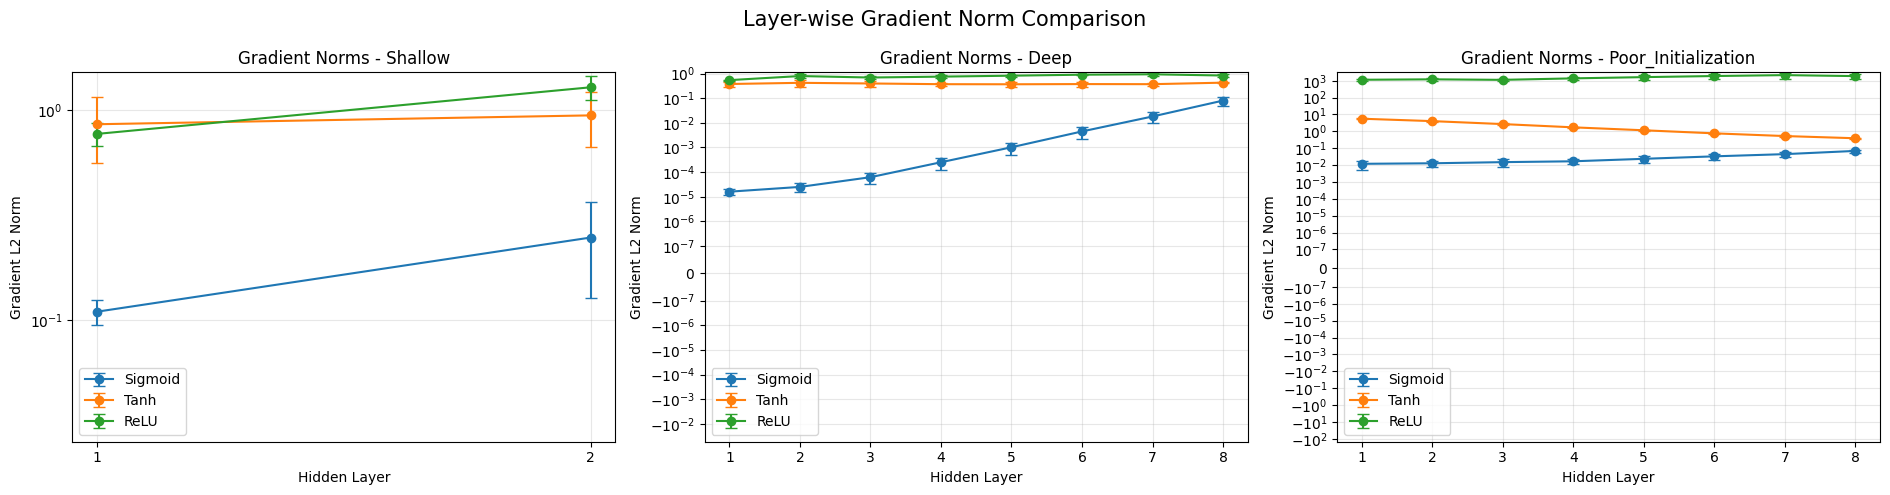

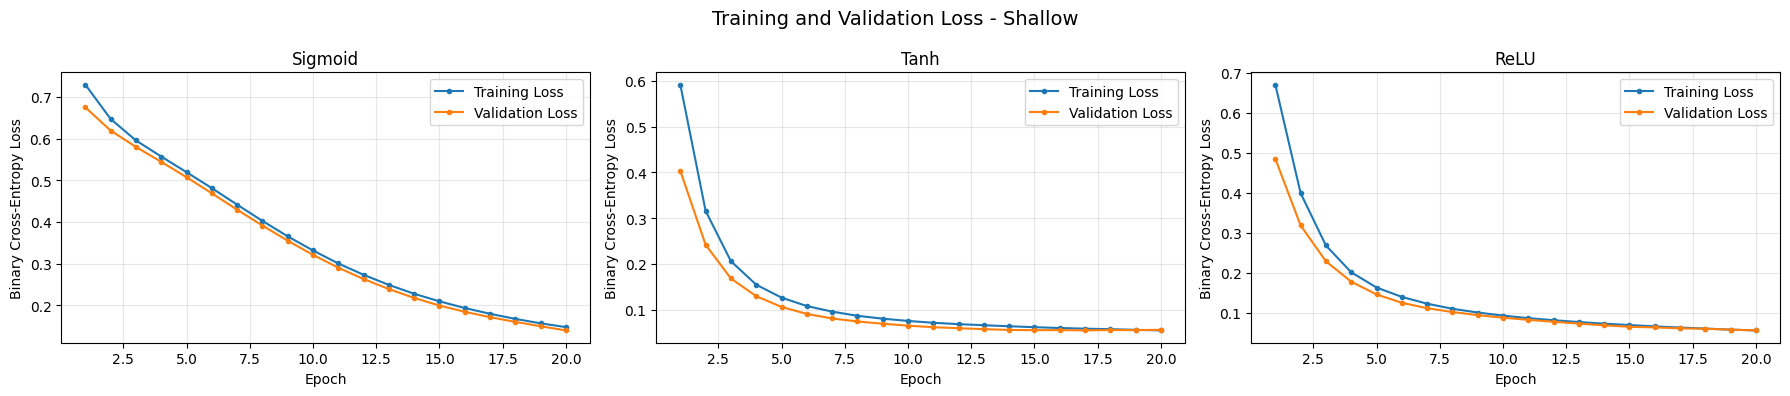

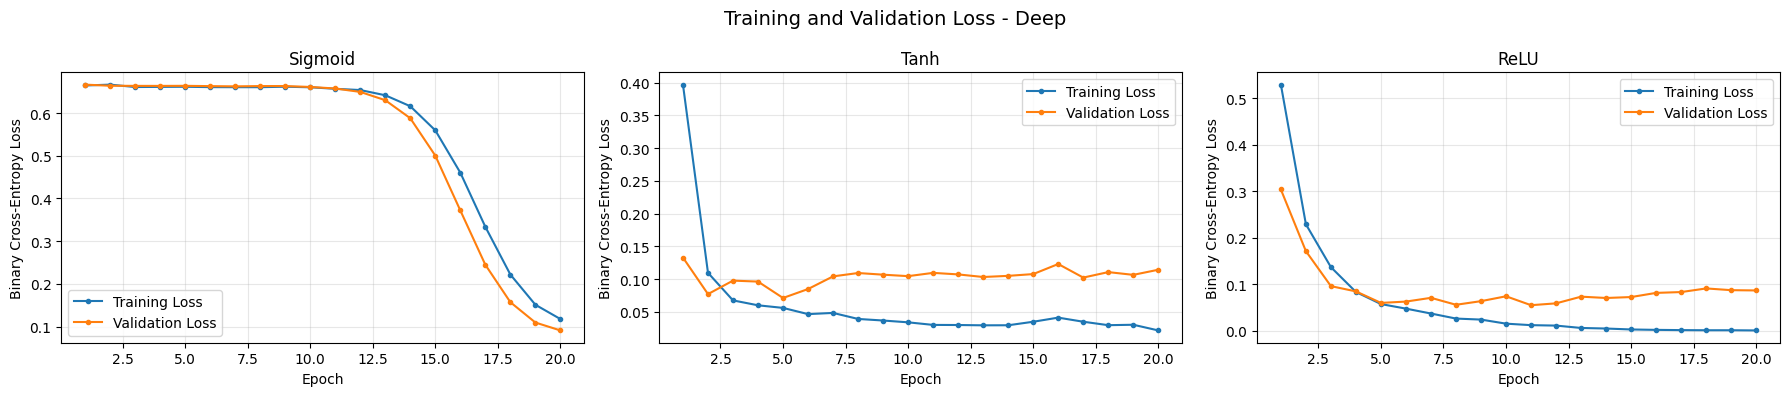

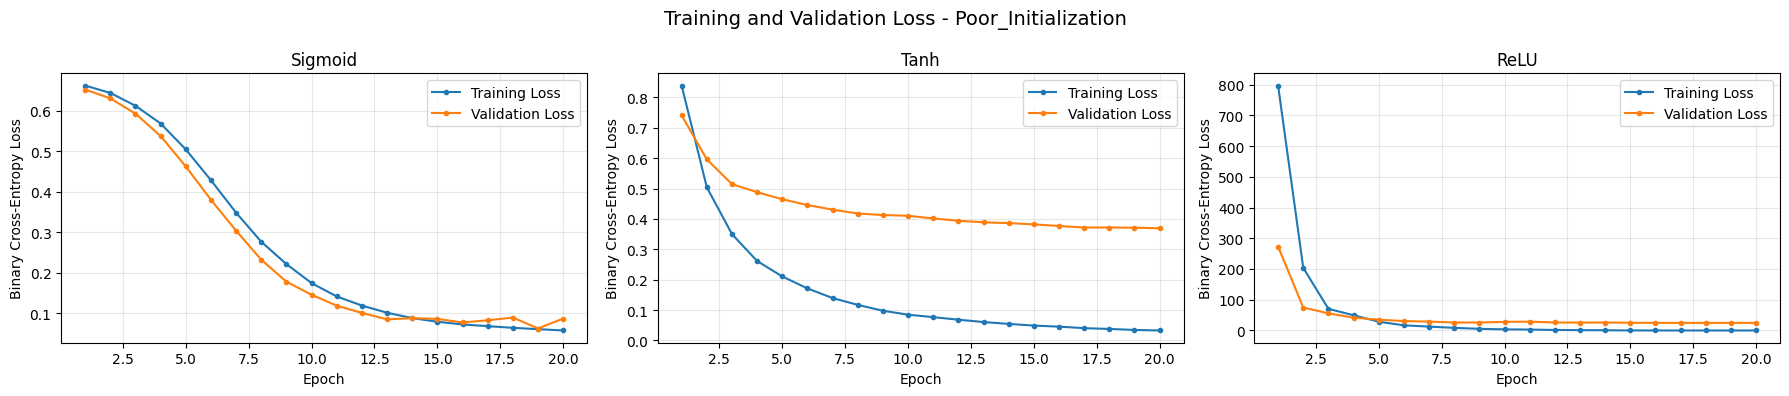

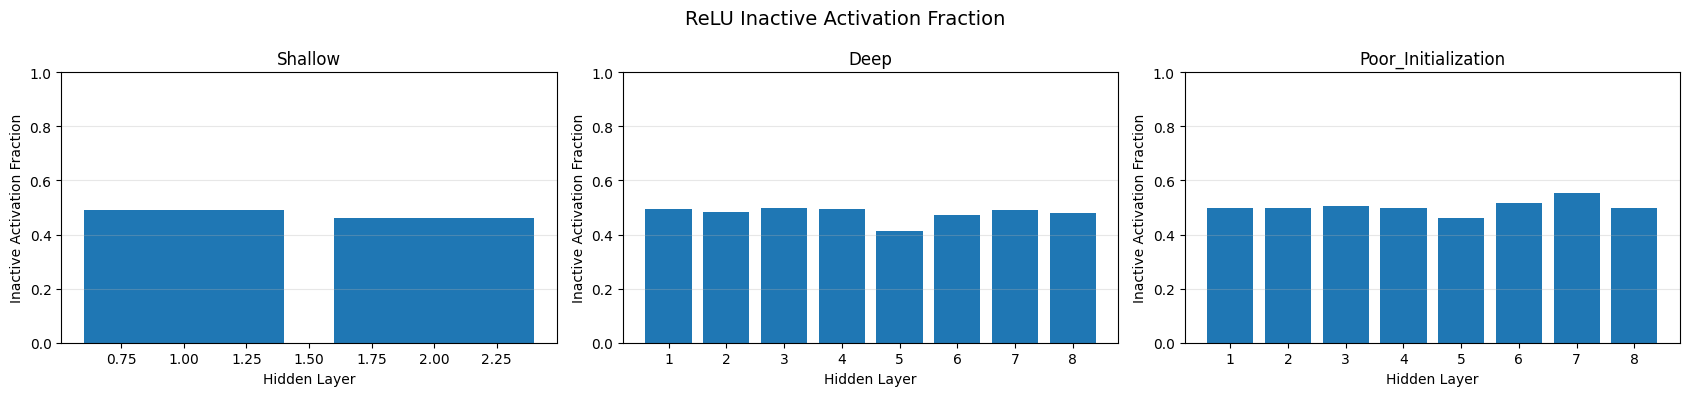

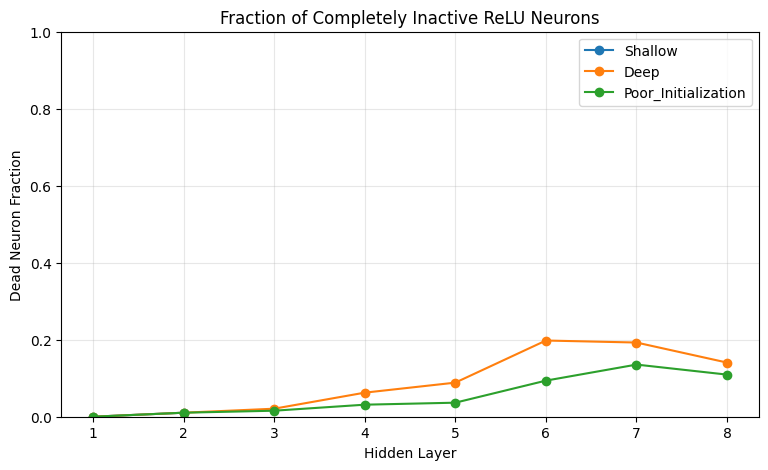

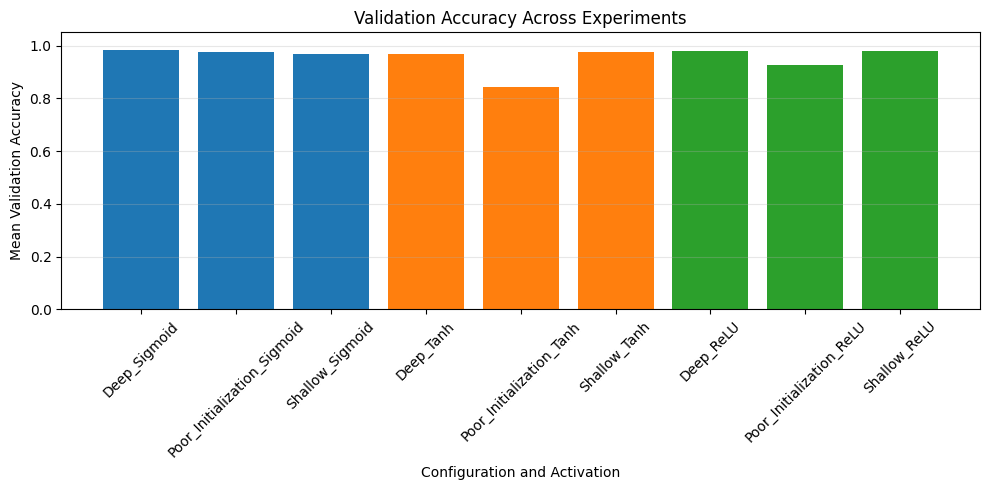

In [ ]:

# ============================================================
# Q1 - CELL 5: EXPERIMENTAL VISUALISATIONS
# ============================================================

# ------------------------------------------------------------
# GRAPH 1: LAYER-WISE GRADIENT NORMS
# ------------------------------------------------------------

config_names = list(CONFIGURATIONS.keys())

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 5),
    sharey=False
)

for ax, config_name in zip(axes, config_names):

    subset = gradient_summary[
        gradient_summary["Configuration"] == config_name
    ]

    for activation in ACTIVATIONS:

        part = subset[
            subset["Activation"] == activation
        ].sort_values("Layer")

        ax.errorbar(
            part["Layer"],
            part["Mean_Gradient"],
            yerr=part["Std_Gradient"],
            marker="o",
            capsize=4,
            label=activation
        )

    ax.set_title(
        f"Gradient Norms - {config_name}"
    )

    ax.set_xlabel("Hidden Layer")
    ax.set_ylabel("Gradient L2 Norm")

    ax.set_xticks(
        range(
            1,
            max(
                len(CONFIGURATIONS[config_name]["hidden_sizes"]),
                2
            ) + 1
        )
    )

    ax.set_yscale("symlog", linthresh=1e-7)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "Layer-wise Gradient Norm Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 2: TRAINING AND VALIDATION LOSS CURVES
# ------------------------------------------------------------

for config_name in config_names:

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 4)
    )

    for ax, activation in zip(axes, ACTIVATIONS):

        subset = history_df[
            (history_df["Configuration"] == config_name) &
            (history_df["Activation"] == activation)
        ]

        loss_summary = (
            subset
            .groupby("Epoch")
            .agg(
                Train_Mean=("Train_Loss", "mean"),
                Train_Std=("Train_Loss", "std"),
                Val_Mean=("Validation_Loss", "mean"),
                Val_Std=("Validation_Loss", "std")
            )
            .reset_index()
        )

        ax.plot(
            loss_summary["Epoch"],
            loss_summary["Train_Mean"],
            label="Training Loss",
            marker="."
        )

        ax.plot(
            loss_summary["Epoch"],
            loss_summary["Val_Mean"],
            label="Validation Loss",
            marker="."
        )

        ax.set_title(activation)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Binary Cross-Entropy Loss")
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.suptitle(
        f"Training and Validation Loss - {config_name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# GRAPH 3: RELU INACTIVE ACTIVATION FRACTION
# ------------------------------------------------------------

if not relu_df.empty:

    fig, axes = plt.subplots(
        1, 3,
        figsize=(17, 4)
    )

    for ax, config_name in zip(axes, config_names):

        subset = relu_df[
            relu_df["Configuration"] == config_name
        ]

        grouped = (
            subset
            .groupby("Layer")
            ["Inactive_Activation_Fraction"]
            .mean()
            .reset_index()
        )

        ax.bar(
            grouped["Layer"],
            grouped["Inactive_Activation_Fraction"]
        )

        ax.set_title(config_name)
        ax.set_xlabel("Hidden Layer")
        ax.set_ylabel("Inactive Activation Fraction")
        ax.set_ylim(0, 1)
        ax.grid(axis="y", alpha=0.3)

    plt.suptitle(
        "ReLU Inactive Activation Fraction",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# GRAPH 4: DEAD RELU NEURON FRACTION
# ------------------------------------------------------------

if not relu_df.empty:

    fig, ax = plt.subplots(figsize=(9, 5))

    for config_name in config_names:

        subset = relu_df[
            relu_df["Configuration"] == config_name
        ]

        grouped = (
            subset
            .groupby("Layer")["Dead_Neuron_Fraction"]
            .mean()
        )

        ax.plot(
            grouped.index,
            grouped.values,
            marker="o",
            label=config_name
        )

    ax.set_title("Fraction of Completely Inactive ReLU Neurons")
    ax.set_xlabel("Hidden Layer")
    ax.set_ylabel("Dead Neuron Fraction")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.show()


# ------------------------------------------------------------
# GRAPH 5: VALIDATION ACCURACY COMPARISON
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

for activation in ACTIVATIONS:

    subset = performance_summary[
        performance_summary["Activation"] == activation
    ]

    ax.bar(
        subset["Configuration"] + "_" + activation,
        subset["Val_Accuracy_Mean"],
        label=activation
    )

ax.set_title("Validation Accuracy Across Experiments")
ax.set_xlabel("Configuration and Activation")
ax.set_ylabel("Mean Validation Accuracy")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# Q1 - CELL 6: EXPORT ALL EXPERIMENTAL EVIDENCE
# ============================================================

import json
import zipfile
from google.colab import files

OUTPUT_DIR = "Q1_Experimental_Evidence"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save raw experimental data
performance_df.to_csv(
    f"{OUTPUT_DIR}/performance_raw.csv",
    index=False
)

gradient_df.to_csv(
    f"{OUTPUT_DIR}/gradient_norms_raw.csv",
    index=False
)

history_df.to_csv(
    f"{OUTPUT_DIR}/training_history.csv",
    index=False
)

relu_df.to_csv(
    f"{OUTPUT_DIR}/relu_analysis.csv",
    index=False
)

performance_summary.to_csv(
    f"{OUTPUT_DIR}/performance_summary.csv",
    index=False
)

gradient_summary.to_csv(
    f"{OUTPUT_DIR}/gradient_summary.csv",
    index=False
)

parameter_df.to_csv(
    f"{OUTPUT_DIR}/parameter_counts.csv",
    index=False
)

if not relu_df.empty:
    relu_summary.to_csv(
        f"{OUTPUT_DIR}/relu_summary.csv",
        index=False
    )

# Save experiment settings
experiment_settings = {
    "Dataset": "Wisconsin Breast Cancer Diagnostic",
    "Samples": 569,
    "Features": 30,
    "Split": "70% training, 15% validation, 15% testing",
    "Random_Seeds": SEEDS,
    "Batch_Size": BATCH_SIZE,
    "Epochs": EPOCHS,
    "Optimizer": "Adam",
    "Learning_Rate": LEARNING_RATE,
    "Activations": ACTIVATIONS,
    "Configurations": CONFIGURATIONS,
    "Device": str(device)
}

with open(
    f"{OUTPUT_DIR}/experiment_settings.json",
    "w"
) as f:

    json.dump(
        experiment_settings,
        f,
        indent=4
    )

# Save figures generated in Cell 5 separately
# (Re-run or save individual plots with plt.savefig
# if you want high-resolution standalone figures.)

# Create ZIP archive
zip_filename = "Q1_Experimental_Evidence.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for root, dirs, filenames in os.walk(OUTPUT_DIR):

        for filename in filenames:

            full_path = os.path.join(root, filename)

            archive.write(
                full_path,
                arcname=os.path.relpath(
                    full_path,
                    OUTPUT_DIR
                )
            )

print("Evidence exported successfully.")
print("Files included:")

for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

print("\nDownloading ZIP file...")

files.download(zip_filename)


Evidence exported successfully.
Files included:
- gradient_summary.csv
- relu_summary.csv
- gradient_norms_raw.csv
- relu_analysis.csv
- performance_summary.csv
- performance_raw.csv
- parameter_counts.csv
- experiment_settings.json
- training_history.csv



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# Q2 - CELL 1: IMPORTS AND SYNTHETIC DATASET
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# ------------------------------------------------------------
# GENERATE SYNTHETIC HOSPITAL READMISSION DATA
# ------------------------------------------------------------

N = 1000

age = np.random.randint(20, 90, N)
length_of_stay = np.random.randint(1, 31, N)
previous_admissions = np.random.poisson(1.5, N)
medications = np.random.randint(1, 16, N)

X = np.column_stack([
    age,
    length_of_stay,
    previous_admissions,
    medications
]).astype(np.float64)

# Generate readmission probability using a
# nonlinear logistic relationship

logit = (
    -3.5
    + 0.035 * age
    + 0.065 * length_of_stay
    + 0.65 * previous_admissions
    + 0.09 * medications
    + 0.012 * length_of_stay * previous_admissions
)

probability = 1 / (1 + np.exp(-logit))

y = (
    np.random.rand(N) < probability
).astype(np.float64).reshape(-1, 1)

# ------------------------------------------------------------
# TRAIN / VALIDATION / TEST SPLIT
# ------------------------------------------------------------

indices = np.random.permutation(N)

train_end = int(0.70 * N)
val_end = int(0.85 * N)

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

X_train = X[train_idx]
X_val = X[val_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

# Standardise using training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

print("=" * 55)
print("DATASET INFORMATION")
print("=" * 55)

print("Dataset: Synthetic Hospital Readmission")
print("Total samples:", N)
print("Input features:", X.shape[1])
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nClass distribution:")
print(pd.Series(y.flatten()).value_counts().sort_index())

print("\nFeature names:")
print([
    "Age",
    "Length of Stay",
    "Previous Admissions",
    "Medications"
])

print("\nDataset preparation completed.")


DATASET INFORMATION
Dataset: Synthetic Hospital Readmission
Total samples: 1000
Input features: 4
Training samples: 700
Validation samples: 150
Testing samples: 150

Class distribution:
0.0    258
1.0    742
Name: count, dtype: int64

Feature names:
['Age', 'Length of Stay', 'Previous Admissions', 'Medications']

Dataset preparation completed.


In [ ]:

# ============================================================
# Q2 - CELL 2: ACTIVATION, LOSS AND FORWARD PROPAGATION
# ============================================================

def sigmoid(z):

    # Numerically stable sigmoid
    z = np.clip(z, -500, 500)

    return 1.0 / (1.0 + np.exp(-z))


def binary_cross_entropy(y_true, y_pred):

    epsilon = 1e-12

    y_pred = np.clip(
        y_pred,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


# ------------------------------------------------------------
# INITIALISE PARAMETERS
# ------------------------------------------------------------

INPUT_SIZE = 4
HIDDEN_SIZE = 8
OUTPUT_SIZE = 1

rng = np.random.default_rng(42)

W1 = rng.normal(
    0, np.sqrt(1 / INPUT_SIZE),
    (INPUT_SIZE, HIDDEN_SIZE)
)

b1 = np.zeros((1, HIDDEN_SIZE))

W2 = rng.normal(
    0, np.sqrt(1 / HIDDEN_SIZE),
    (HIDDEN_SIZE, OUTPUT_SIZE)
)

b2 = np.zeros((1, OUTPUT_SIZE))


# ------------------------------------------------------------
# FORWARD PROPAGATION
# ------------------------------------------------------------

def forward_propagation(X, W1, b1, W2, b2):

    Z1 = X @ W1 + b1

    A1 = sigmoid(Z1)

    Z2 = A1 @ W2 + b2

    A2 = sigmoid(Z2)

    cache = {
        "X": X,
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "A2": A2
    }

    return A2, cache


# ------------------------------------------------------------
# TEST FORWARD PASS
# ------------------------------------------------------------

sample_X = X_train[:5]
sample_y = y_train[:5]

predictions, cache = forward_propagation(
    sample_X, W1, b1, W2, b2
)

loss = binary_cross_entropy(
    sample_y, predictions
)

print("Forward propagation completed.")

print("\nW1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

print("\nPredicted probabilities:")
print(predictions)

print("\nActual labels:")
print(sample_y)

print("\nInitial binary cross-entropy loss:")
print(loss)




Forward propagation completed.

W1 shape: (4, 8)
b1 shape: (1, 8)
W2 shape: (8, 1)
b2 shape: (1, 1)

Predicted probabilities:
[[0.50170493]
 [0.43823857]
 [0.49865846]
 [0.43884954]
 [0.42775647]]

Actual labels:
[[1.]
 [1.]
 [1.]
 [0.]
 [1.]]

Initial binary cross-entropy loss:
0.727507256588311


In [ ]:

# ============================================================
# Q2 - CELL 3: MANUAL BACKPROPAGATION
# ============================================================

def backward_propagation(y_true, cache, W2):

    X = cache["X"]
    A1 = cache["A1"]
    A2 = cache["A2"]

    m = X.shape[0]

    # Output layer gradient
    dZ2 = (A2 - y_true) / m

    dW2 = A1.T @ dZ2

    db2 = np.sum(
        dZ2,
        axis=0,
        keepdims=True
    )

    # Hidden layer gradient
    dA1 = dZ2 @ W2.T

    # Derivative of sigmoid
    dZ1 = dA1 * A1 * (1 - A1)

    dW1 = X.T @ dZ1

    db1 = np.sum(
        dZ1,
        axis=0,
        keepdims=True
    )

    gradients = {
        "W1": dW1,
        "b1": db1,
        "W2": dW2,
        "b2": db2
    }

    return gradients


# ------------------------------------------------------------
# TEST BACKPROPAGATION
# ------------------------------------------------------------

predictions, cache = forward_propagation(
    sample_X, W1, b1, W2, b2
)

gradients = backward_propagation(
    sample_y, cache, W2
)

print("=" * 55)
print("ANALYTICAL GRADIENTS")
print("=" * 55)

for name, gradient in gradients.items():

    print(
        f"{name}: Shape = {gradient.shape}, "
        f"Gradient norm = {np.linalg.norm(gradient):.10f}"
    )

print("\nBackpropagation completed successfully.")


ANALYTICAL GRADIENTS
W1: Shape = (4, 8), Gradient norm = 0.1019977107
b1: Shape = (1, 8), Gradient norm = 0.0542404011
W2: Shape = (8, 1), Gradient norm = 0.5366364599
b2: Shape = (1, 1), Gradient norm = 0.3389584053

Backpropagation completed successfully.


In [ ]:

# ============================================================
# Q2 - CELL 4: NUMERICAL GRADIENT CHECKING
# ============================================================

def compute_loss(X, y, params):

    predictions, _ = forward_propagation(
        X,
        params["W1"],
        params["b1"],
        params["W2"],
        params["b2"]
    )

    return binary_cross_entropy(y, predictions)


def numerical_gradient(
    X, y, params, parameter_name, epsilon
):

    parameter = params[parameter_name]

    numerical_grad = np.zeros_like(parameter)

    for index in np.ndindex(parameter.shape):

        original_value = parameter[index]

        # Positive perturbation
        parameter[index] = original_value + epsilon

        loss_plus = compute_loss(X, y, params)

        # Negative perturbation
        parameter[index] = original_value - epsilon

        loss_minus = compute_loss(X, y, params)

        # Restore original parameter
        parameter[index] = original_value

        numerical_grad[index] = (
            loss_plus - loss_minus
        ) / (2 * epsilon)

    return numerical_grad


def relative_error(analytical, numerical):

    numerator = np.linalg.norm(
        analytical - numerical
    )

    denominator = (
        np.linalg.norm(analytical)
        + np.linalg.norm(numerical)
        + 1e-12
    )

    return numerator / denominator


# ------------------------------------------------------------
# GRADIENT CHECK ON A SMALL FIXED BATCH
# ------------------------------------------------------------

check_X = X_train[:8].copy()
check_y = y_train[:8].copy()

original_params = {
    "W1": W1.copy(),
    "b1": b1.copy(),
    "W2": W2.copy(),
    "b2": b2.copy()
}

_, check_cache = forward_propagation(
    check_X,
    original_params["W1"],
    original_params["b1"],
    original_params["W2"],
    original_params["b2"]
)

analytical_gradients = backward_propagation(
    check_y,
    check_cache,
    original_params["W2"]
)

EPSILONS = [1e-5, 1e-6]

gradient_check_results = []

for epsilon in EPSILONS:

    for parameter_name in ["W1", "b1", "W2", "b2"]:

        numerical_grad = numerical_gradient(
            check_X,
            check_y,
            original_params,
            parameter_name,
            epsilon
        )

        analytical_grad = analytical_gradients[
            parameter_name
        ]

        error = relative_error(
            analytical_grad,
            numerical_grad
        )

        gradient_check_results.append({

            "Epsilon": epsilon,
            "Parameter": parameter_name,

            "Analytical_Norm":
                np.linalg.norm(analytical_grad),

            "Numerical_Norm":
                np.linalg.norm(numerical_grad),

            "Relative_Error": error

        })


gradient_check_df = pd.DataFrame(
    gradient_check_results
)

print("=" * 65)
print("NUMERICAL GRADIENT VERIFICATION")
print("=" * 65)

display(
    gradient_check_df.round(12)
)

print("\nVerification interpretation:")

for _, row in gradient_check_df.iterrows():

    if row["Relative_Error"] < 1e-7:
        status = "Excellent agreement"

    elif row["Relative_Error"] < 1e-5:
        status = "Acceptable agreement"

    else:
        status = "Requires investigation"

    print(
        row["Parameter"],
        "| Epsilon:", row["Epsilon"],
        "|", status
    )


NUMERICAL GRADIENT VERIFICATION


,Epsilon,Parameter,Analytical_Norm,Numerical_Norm,Relative_Error
0,0.000010,W1,0.085433,0.085433,1.360000e-10
1,0.000010,b1,0.046849,0.046849,9.700000e-11
2,0.000010,W2,0.457323,0.457323,1.400000e-11
3,0.000010,b2,0.285650,0.285650,7.000000e-12
4,0.000001,W1,0.085433,0.085433,1.521000e-09
5,0.000001,b1,0.046849,0.046849,1.320000e-09
6,0.000001,W2,0.457323,0.457323,1.800000e-10
7,0.000001,b2,0.285650,0.285650,6.100000e-11



Verification interpretation:
W1 | Epsilon: 1e-05 | Excellent agreement
b1 | Epsilon: 1e-05 | Excellent agreement
W2 | Epsilon: 1e-05 | Excellent agreement
b2 | Epsilon: 1e-05 | Excellent agreement
W1 | Epsilon: 1e-06 | Excellent agreement
b1 | Epsilon: 1e-06 | Excellent agreement
W2 | Epsilon: 1e-06 | Excellent agreement
b2 | Epsilon: 1e-06 | Excellent agreement


In [ ]:

# ============================================================
# Q2 - CELL 5: MANUAL PARAMETER UPDATE
# ============================================================

def update_parameters(params, gradients, learning_rate):

    updated_params = {}

    for name in params:

        updated_params[name] = (
            params[name]
            - learning_rate * gradients[name]
        )

    return updated_params


LEARNING_RATE = 0.1

updated_params = update_parameters(
    original_params,
    analytical_gradients,
    LEARNING_RATE
)

print("=" * 55)
print("PARAMETER UPDATE VERIFICATION")
print("=" * 55)

for name in original_params:

    difference = np.linalg.norm(
        updated_params[name] - original_params[name]
    )

    print(
        name,
        "| Original norm:",
        round(np.linalg.norm(original_params[name]), 6),
        "| Updated norm:",
        round(np.linalg.norm(updated_params[name]), 6),
        "| Change:",
        round(difference, 10)
    )

print("\nParameter update completed.")


PARAMETER UPDATE VERIFICATION
W1 | Original norm: 2.358874 | Updated norm: 2.359811 | Change: 0.0085433482
b1 | Original norm: 0.0 | Updated norm: 0.004685 | Change: 0.0046849446
W2 | Original norm: 0.741663 | Updated norm: 0.741186 | Change: 0.0457323401
b2 | Original norm: 0.0 | Updated norm: 0.028565 | Change: 0.0285649662

Parameter update completed.


In [ ]:

# ============================================================
# Q2 - CELL 6: DELIBERATE BACKPROPAGATION BUG
# ============================================================

def buggy_backward_propagation(y_true, cache, W2):

    X = cache["X"]
    A1 = cache["A1"]
    A2 = cache["A2"]

    m = X.shape[0]

    # Output layer gradients remain correct
    dZ2 = (A2 - y_true) / m

    dW2 = A1.T @ dZ2

    db2 = np.sum(
        dZ2,
        axis=0,
        keepdims=True
    )

    # Hidden layer gradient
    dA1 = dZ2 @ W2.T

    # DELIBERATE BUG:
    # Missing sigmoid derivative A1 * (1 - A1)
    dZ1 = dA1

    dW1 = X.T @ dZ1

    db1 = np.sum(
        dZ1,
        axis=0,
        keepdims=True
    )

    return {
        "W1": dW1,
        "b1": db1,
        "W2": dW2,
        "b2": db2
    }


# ------------------------------------------------------------
# COMPARE BUGGY GRADIENTS WITH NUMERICAL GRADIENTS
# ------------------------------------------------------------

buggy_gradients = buggy_backward_propagation(
    check_y,
    check_cache,
    original_params["W2"]
)

bug_results = []

epsilon = 1e-5

for parameter_name in ["W1", "b1", "W2", "b2"]:

    numerical_grad = numerical_gradient(
        check_X,
        check_y,
        original_params,
        parameter_name,
        epsilon
    )

    buggy_grad = buggy_gradients[parameter_name]

    error = relative_error(
        buggy_grad,
        numerical_grad
    )

    bug_results.append({

        "Parameter": parameter_name,

        "Buggy_Gradient_Norm":
            np.linalg.norm(buggy_grad),

        "Numerical_Gradient_Norm":
            np.linalg.norm(numerical_grad),

        "Relative_Error": error,

        "Detected": error > 1e-5

    })


bug_df = pd.DataFrame(bug_results)

print("=" * 65)
print("DELIBERATE BUG DETECTION")
print("=" * 65)

display(bug_df.round(10))

print("\nBug detection result:")

for _, row in bug_df.iterrows():

    if row["Detected"]:
        print(
            row["Parameter"],
            ": BUG DETECTED"
        )

    else:
        print(
            row["Parameter"],
            ": Gradient verification passed"
        )


DELIBERATE BUG DETECTION


,Parameter,Buggy_Gradient_Norm,Numerical_Gradient_Norm,Relative_Error,Detected
0,W1,0.405853,0.085433,0.654041,True
1,b1,0.211856,0.046849,0.640089,True
2,W2,0.457323,0.457323,0.000000,False
3,b2,0.285650,0.285650,0.000000,False



Bug detection result:
W1 : BUG DETECTED
b1 : BUG DETECTED
W2 : Gradient verification passed
b2 : Gradient verification passed


In [ ]:

# ============================================================
# Q2 - CELL 7: COMPLETE NUMPY TRAINING LOOP
# ============================================================

def train_numpy_network(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_size=8,
    epochs=100,
    batch_size=32,
    learning_rate=0.1,
    seed=42
):

    rng = np.random.default_rng(seed)

    input_size = X_train.shape[1]

    # Xavier-style initialisation
    W1 = rng.normal(
        0,
        np.sqrt(2 / (input_size + hidden_size)),
        (input_size, hidden_size)
    )

    b1 = np.zeros((1, hidden_size))

    W2 = rng.normal(
        0,
        np.sqrt(2 / (hidden_size + 1)),
        (hidden_size, 1)
    )

    b2 = np.zeros((1, 1))

    params = {
        "W1": W1,
        "b1": b1,
        "W2": W2,
        "b2": b2
    }

    history = []

    for epoch in range(epochs):

        # Shuffle training samples
        indices = rng.permutation(len(X_train))

        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            xb = X_shuffled[start:end]
            yb = y_shuffled[start:end]

            # Forward pass
            predictions, cache = forward_propagation(
                xb,
                params["W1"],
                params["b1"],
                params["W2"],
                params["b2"]
            )

            # Backward pass
            gradients = backward_propagation(
                yb,
                cache,
                params["W2"]
            )

            # Update parameters
            params = update_parameters(
                params,
                gradients,
                learning_rate
            )

        # Calculate epoch losses
        train_predictions, _ = forward_propagation(
            X_train,
            params["W1"],
            params["b1"],
            params["W2"],
            params["b2"]
        )

        val_predictions, _ = forward_propagation(
            X_val,
            params["W1"],
            params["b1"],
            params["W2"],
            params["b2"]
        )

        train_loss = binary_cross_entropy(
            y_train,
            train_predictions
        )

        val_loss = binary_cross_entropy(
            y_val,
            val_predictions
        )

        history.append({

            "Epoch": epoch + 1,
            "Training_Loss": train_loss,
            "Validation_Loss": val_loss

        })

        if (epoch + 1) % 10 == 0:

            print(
                f"Epoch {epoch+1:03d}/{epochs} | "
                f"Train Loss: {train_loss:.5f} | "
                f"Val Loss: {val_loss:.5f}"
            )

    return params, pd.DataFrame(history)


# ------------------------------------------------------------
# TRAIN THE NETWORK
# ------------------------------------------------------------

trained_params, training_history = train_numpy_network(
    X_train,
    y_train,
    X_val,
    y_val,
    hidden_size=8,
    epochs=100,
    batch_size=32,
    learning_rate=0.1,
    seed=42
)

print("\nNumPy training completed.")


Epoch 010/100 | Train Loss: 0.49979 | Val Loss: 0.47654
Epoch 020/100 | Train Loss: 0.47804 | Val Loss: 0.43633
Epoch 030/100 | Train Loss: 0.47260 | Val Loss: 0.42027
Epoch 040/100 | Train Loss: 0.47125 | Val Loss: 0.41359
Epoch 050/100 | Train Loss: 0.47102 | Val Loss: 0.41051
Epoch 060/100 | Train Loss: 0.47080 | Val Loss: 0.40934
Epoch 070/100 | Train Loss: 0.47074 | Val Loss: 0.40867
Epoch 080/100 | Train Loss: 0.47079 | Val Loss: 0.40845
Epoch 090/100 | Train Loss: 0.47078 | Val Loss: 0.40856
Epoch 100/100 | Train Loss: 0.47055 | Val Loss: 0.40834

NumPy training completed.


NUMPY NETWORK TEST RESULTS
Test loss: 0.403715
Test accuracy: 0.8267
Test precision: 0.8583
Test recall: 0.9316

Confusion matrix:
Predicted   0    1
Actual            
0.0        15   18
1.0         8  109


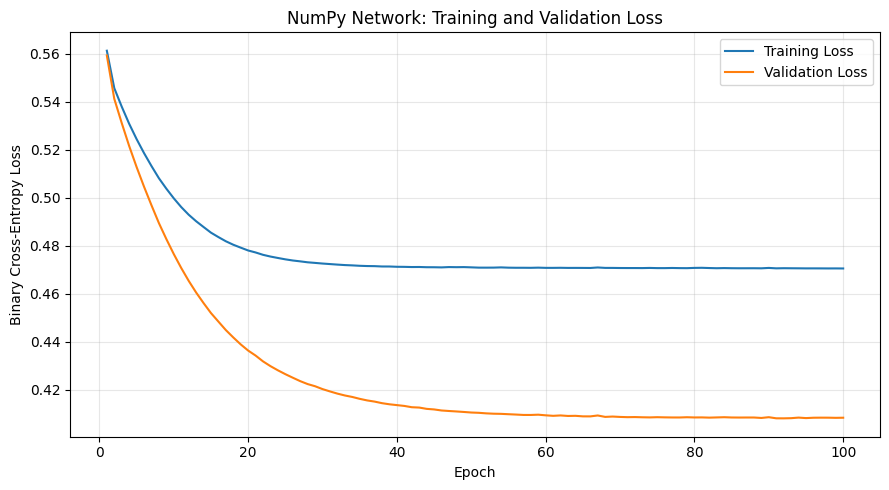

In [ ]:

# ============================================================
# Q2 - CELL 8: MODEL EVALUATION
# ============================================================

test_probabilities, _ = forward_propagation(
    X_test,
    trained_params["W1"],
    trained_params["b1"],
    trained_params["W2"],
    trained_params["b2"]
)

test_predictions = (
    test_probabilities >= 0.5
).astype(int)

test_loss = binary_cross_entropy(
    y_test,
    test_probabilities
)

test_accuracy = np.mean(
    test_predictions == y_test
)

test_precision = (
    np.sum((test_predictions == 1) & (y_test == 1))
    /
    max(np.sum(test_predictions == 1), 1)
)

test_recall = (
    np.sum((test_predictions == 1) & (y_test == 1))
    /
    max(np.sum(y_test == 1), 1)
)

print("=" * 55)
print("NUMPY NETWORK TEST RESULTS")
print("=" * 55)

print("Test loss:", round(test_loss, 6))
print("Test accuracy:", round(test_accuracy, 4))
print("Test precision:", round(test_precision, 4))
print("Test recall:", round(test_recall, 4))

print("\nConfusion matrix:")

print(
    pd.crosstab(
        pd.Series(y_test.flatten(), name="Actual"),
        pd.Series(test_predictions.flatten(), name="Predicted")
    )
)

# Plot training and validation losses

plt.figure(figsize=(9, 5))

plt.plot(
    training_history["Epoch"],
    training_history["Training_Loss"],
    label="Training Loss"
)

plt.plot(
    training_history["Epoch"],
    training_history["Validation_Loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("NumPy Network: Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# Q2 - CELL 9: EXPORT RESULTS
# ============================================================

import os
import json
import zipfile

OUTPUT_DIR = "Q2_Experimental_Evidence"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save gradient verification
gradient_check_df.to_csv(
    f"{OUTPUT_DIR}/gradient_check_results.csv",
    index=False
)

# Save deliberate bug results
bug_df.to_csv(
    f"{OUTPUT_DIR}/bug_detection_results.csv",
    index=False
)

# Save training history
training_history.to_csv(
    f"{OUTPUT_DIR}/training_history.csv",
    index=False
)

# Save test predictions
pd.DataFrame({
    "Actual": y_test.flatten(),
    "Predicted": test_predictions.flatten(),
    "Probability": test_probabilities.flatten()
}).to_csv(
    f"{OUTPUT_DIR}/test_predictions.csv",
    index=False
)

# Save trained parameters
np.savez(
    f"{OUTPUT_DIR}/trained_parameters.npz",
    **trained_params
)

# Save experiment settings and metrics
settings = {

    "Dataset": "Synthetic Hospital Readmission",
    "Samples": 1000,
    "Input_Features": 4,

    "Train_Samples": len(X_train),
    "Validation_Samples": len(X_val),
    "Test_Samples": len(X_test),

    "Hidden_Neurons": 8,
    "Output_Neurons": 1,

    "Activation": "Sigmoid",
    "Loss": "Binary Cross Entropy",

    "Optimizer": "Manual Gradient Descent",
    "Learning_Rate": 0.1,
    "Epochs": 100,
    "Batch_Size": 32,

    "Epsilon_Values": EPSILONS,

    "Test_Loss": float(test_loss),
    "Test_Accuracy": float(test_accuracy),
    "Test_Precision": float(test_precision),
    "Test_Recall": float(test_recall)

}

with open(
    f"{OUTPUT_DIR}/experiment_settings.json",
    "w"
) as f:

    json.dump(settings, f, indent=4)

# Package all evidence
zip_filename = "Q2_Experimental_Evidence.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for root, dirs, filenames in os.walk(OUTPUT_DIR):

        for filename in filenames:

            full_path = os.path.join(root, filename)

            archive.write(
                full_path,
                arcname=os.path.relpath(
                    full_path,
                    OUTPUT_DIR
                )
            )

print("=" * 55)
print("Q2 EVIDENCE EXPORT COMPLETED")
print("=" * 55)

for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

print("\nDownloading evidence ZIP...")

from google.colab import files
files.download(zip_filename)


Q2 EVIDENCE EXPORT COMPLETED
- trained_parameters.npz
- gradient_check_results.csv
- bug_detection_results.csv
- experiment_settings.json
- test_predictions.csv
- training_history.csv



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# Q3 - CELL 1: IMPORTS AND DATASET PREPARATION
# ============================================================

import os
import json
import time
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

MASTER_SEED = 42
set_seed(MASTER_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)

# Load dataset
dataset = load_breast_cancer()

X = dataset.data.astype(np.float32)
y = dataset.target.astype(np.float32)

# Split: 70% train, 15% validation, 15% test
X_train_full, X_temp, y_train_full, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Standardise using full training partition only
scaler = StandardScaler()

X_train_full = scaler.fit_transform(
    X_train_full
).astype(np.float32)

X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# Create a deliberately small training subset
small_indices, _ = train_test_split(
    np.arange(len(X_train_full)),
    train_size=0.20,
    random_state=42,
    stratify=y_train_full
)

X_train_small = X_train_full[small_indices]
y_train_small = y_train_full[small_indices]

print("\nDataset:", X.shape)
print("Full training samples:", len(X_train_full))
print("Small training samples:", len(X_train_small))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nTraining class distribution:")
print(pd.Series(y_train_full).value_counts())

print("\nDataset preparation completed.")


PyTorch: 2.14.1+cpu
Device: cpu

Dataset: (569, 30)
Full training samples: 398
Small training samples: 79
Validation samples: 85
Test samples: 86

Training class distribution:
1.0    250
0.0    148
Name: count, dtype: int64

Dataset preparation completed.


In [ ]:


# ============================================================
# Q3 - CELL 2: MODEL AND REGULARIZATION CONFIGURATIONS
# ============================================================

class RegularizedNetwork(nn.Module):

    def __init__(self, dropout_rate=0.0):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(30, 128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)

        )

    def forward(self, x):
        return self.network(x)


EXPERIMENTS = {

    "Baseline": {
        "l1": 0.0,
        "l2": 0.0,
        "dropout": 0.0,
        "early_stopping": False,
        "train_size": "small"
    },

    "L1": {
        "l1": 0.001,
        "l2": 0.0,
        "dropout": 0.0,
        "early_stopping": False,
        "train_size": "small"
    },

    "L2": {
        "l1": 0.0,
        "l2": 0.01,
        "dropout": 0.0,
        "early_stopping": False,
        "train_size": "small"
    },

    "Dropout": {
        "l1": 0.0,
        "l2": 0.0,
        "dropout": 0.40,
        "early_stopping": False,
        "train_size": "small"
    },

    "Early_Stopping": {
        "l1": 0.0,
        "l2": 0.0,
        "dropout": 0.0,
        "early_stopping": True,
        "train_size": "small"
    },

    "Full_Data_Baseline": {
        "l1": 0.0,
        "l2": 0.0,
        "dropout": 0.0,
        "early_stopping": False,
        "train_size": "full"
    }

}

print("Regularization configurations:")

for name, config in EXPERIMENTS.items():
    print(name, ":", config)


Regularization configurations:
Baseline : {'l1': 0.0, 'l2': 0.0, 'dropout': 0.0, 'early_stopping': False, 'train_size': 'small'}
L1 : {'l1': 0.001, 'l2': 0.0, 'dropout': 0.0, 'early_stopping': False, 'train_size': 'small'}
L2 : {'l1': 0.0, 'l2': 0.01, 'dropout': 0.0, 'early_stopping': False, 'train_size': 'small'}
Dropout : {'l1': 0.0, 'l2': 0.0, 'dropout': 0.4, 'early_stopping': False, 'train_size': 'small'}
Early_Stopping : {'l1': 0.0, 'l2': 0.0, 'dropout': 0.0, 'early_stopping': True, 'train_size': 'small'}
Full_Data_Baseline : {'l1': 0.0, 'l2': 0.0, 'dropout': 0.0, 'early_stopping': False, 'train_size': 'full'}


In [ ]:

# ============================================================
# Q3 - CELL 3: TRAINING FUNCTION
# ============================================================

BATCH_SIZE = 16
EPOCHS = 60
LEARNING_RATE = 0.001
PATIENCE = 8
SEEDS = [42, 123, 2026]

criterion = nn.BCEWithLogitsLoss()


def make_loader(X, y, batch_size, shuffle=False, seed=42):

    ds = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator if shuffle else None
    )


def evaluate(model, loader):

    model.eval()

    total_loss = 0
    total = 0
    predictions = []
    actual = []

    with torch.no_grad():

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * len(xb)
            total += len(xb)

            pred = (
                torch.sigmoid(logits) >= 0.5
            ).int()

            predictions.extend(pred.cpu().numpy().flatten())
            actual.extend(yb.cpu().numpy().flatten())

    return {
        "loss": total_loss / total,
        "accuracy": accuracy_score(actual, predictions),
        "precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "recall": recall_score(
            actual, predictions, zero_division=0
        )
    }


def train_experiment(experiment_name, config, seed):

    set_seed(seed)

    # Choose training size
    if config["train_size"] == "small":
        Xtr = X_train_small
        ytr = y_train_small
    else:
        Xtr = X_train_full
        ytr = y_train_full

    train_loader = make_loader(
        Xtr, ytr, BATCH_SIZE, True, seed
    )

    train_eval_loader = make_loader(
        Xtr, ytr, BATCH_SIZE
    )

    val_loader = make_loader(
        X_val, y_val, BATCH_SIZE
    )

    test_loader = make_loader(
        X_test, y_test, BATCH_SIZE
    )

    model = RegularizedNetwork(
        dropout_rate=config["dropout"]
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=config["l2"]
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    history = []

    for epoch in range(EPOCHS):

        model.train()

        epoch_loss = 0
        total_samples = 0

        for xb, yb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)

            base_loss = criterion(logits, yb)

            # L1 regularization
            l1_penalty = sum(
                parameter.abs().sum()
                for name, parameter in model.named_parameters()
                if "weight" in name
            )

            loss = (
                base_loss
                + config["l1"] * l1_penalty
            )

            loss.backward()
            optimizer.step()

            epoch_loss += base_loss.item() * len(xb)
            total_samples += len(xb)

        # Measure training and validation performance
        train_metrics = evaluate(
            model, train_eval_loader
        )

        val_metrics = evaluate(
            model, val_loader
        )

        history.append({

            "Experiment": experiment_name,
            "Seed": seed,
            "Epoch": epoch + 1,

            "Train_Loss": train_metrics["loss"],
            "Val_Loss": val_metrics["loss"],

            "Train_Accuracy": train_metrics["accuracy"],
            "Val_Accuracy": val_metrics["accuracy"]

        })

        # Save best validation model
        if val_metrics["loss"] < best_val_loss - 1e-5:

            best_val_loss = val_metrics["loss"]
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            best_epoch = epoch + 1
            wait = 0

        else:
            wait += 1

        # Early stopping only for the designated condition
        if config["early_stopping"] and wait >= PATIENCE:
            break

    # Restore best validation checkpoint
    if best_state is not None:
        model.load_state_dict(best_state)

    # Final metrics using the restored checkpoint
    train_final = evaluate(model, train_eval_loader)
    val_final = evaluate(model, val_loader)
    test_final = evaluate(model, test_loader)

    # Weight norm
    weight_norm = np.sqrt(
        sum(
            torch.sum(parameter.detach() ** 2).item()
            for name, parameter in model.named_parameters()
            if "weight" in name
        )
    )

    result = {

        "Experiment": experiment_name,
        "Seed": seed,

        "Best_Epoch": best_epoch,

        "Train_Loss": train_final["loss"],
        "Val_Loss": val_final["loss"],

        "Train_Accuracy": train_final["accuracy"],
        "Val_Accuracy": val_final["accuracy"],

        "Test_Accuracy": test_final["accuracy"],
        "Test_Precision": test_final["precision"],
        "Test_Recall": test_final["recall"],

        "Accuracy_Gap": (
            train_final["accuracy"]
            - val_final["accuracy"]
        ),

        "Weight_Norm": weight_norm

    }

    return result, history


print("Training function defined successfully.")


Training function defined successfully.


In [ ]:

# ============================================================
# Q3 - CELL 4: RUN ALL EXPERIMENTS
# ============================================================

all_results = []
all_histories = []

start_time = time.time()

for experiment_name, config in EXPERIMENTS.items():

    for seed in SEEDS:

        print("\n" + "=" * 65)

        print(
            "Experiment:", experiment_name,
            "| Seed:", seed
        )

        result, history = train_experiment(
            experiment_name,
            config,
            seed
        )

        all_results.append(result)
        all_histories.extend(history)

        print(
            "Best epoch:", result["Best_Epoch"],
            "| Validation accuracy:",
            round(result["Val_Accuracy"], 4),
            "| Test accuracy:",
            round(result["Test_Accuracy"], 4)
        )

results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_histories)

print("\n" + "=" * 65)
print("ALL EXPERIMENTS COMPLETED")
print("=" * 65)

print("Total runs:", len(results_df))
print("Total training records:", len(history_df))
print("Execution time:", round(time.time() - start_time, 2), "seconds")

display(results_df.head(10))



Experiment: Baseline | Seed: 42
Best epoch: 10 | Validation accuracy: 0.9647 | Test accuracy: 0.8953

Experiment: Baseline | Seed: 123
Best epoch: 9 | Validation accuracy: 0.9647 | Test accuracy: 0.8953

Experiment: Baseline | Seed: 2026
Best epoch: 9 | Validation accuracy: 0.9529 | Test accuracy: 0.907

Experiment: L1 | Seed: 42
Best epoch: 12 | Validation accuracy: 0.9529 | Test accuracy: 0.8953

Experiment: L1 | Seed: 123
Best epoch: 59 | Validation accuracy: 0.9529 | Test accuracy: 0.9302

Experiment: L1 | Seed: 2026
Best epoch: 45 | Validation accuracy: 0.9529 | Test accuracy: 0.9302

Experiment: L2 | Seed: 42
Best epoch: 10 | Validation accuracy: 0.9529 | Test accuracy: 0.8953

Experiment: L2 | Seed: 123
Best epoch: 9 | Validation accuracy: 0.9647 | Test accuracy: 0.8953

Experiment: L2 | Seed: 2026
Best epoch: 11 | Validation accuracy: 0.9647 | Test accuracy: 0.907

Experiment: Dropout | Seed: 42
Best epoch: 12 | Validation accuracy: 0.9529 | Test accuracy: 0.8953

Experiment: 

,Experiment,Seed,Best_Epoch,Train_Loss,Val_Loss,Train_Accuracy,Val_Accuracy,Test_Accuracy,Test_Precision,Test_Recall,Accuracy_Gap,Weight_Norm
0,Baseline,42,10,0.011456,0.102407,1.000000,0.964706,0.895349,0.881356,0.962963,0.035294,11.186774
1,Baseline,123,9,0.011672,0.094419,1.000000,0.964706,0.895349,0.881356,0.962963,0.035294,11.185116
2,Baseline,2026,9,0.014417,0.111072,1.000000,0.952941,0.906977,0.896552,0.962963,0.047059,11.092950
3,L1,42,12,0.032456,0.112517,0.987342,0.952941,0.895349,0.881356,0.962963,0.034401,6.838164
4,L1,123,59,0.012565,0.117632,1.000000,0.952941,0.930233,0.900000,1.000000,0.047059,3.793207
5,L1,2026,45,0.016438,0.116348,1.000000,0.952941,0.930233,0.900000,1.000000,0.047059,4.040520
6,L2,42,10,0.023398,0.104530,1.000000,0.952941,0.895349,0.881356,0.962963,0.047059,7.896111
7,L2,123,9,0.024424,0.107088,0.987342,0.964706,0.895349,0.881356,0.962963,0.022636,8.287990
8,L2,2026,11,0.020413,0.112273,1.000000,0.964706,0.906977,0.883333,0.981481,0.035294,7.680594
9,Dropout,42,12,0.013643,0.094851,1.000000,0.952941,0.895349,0.881356,0.962963,0.047059,11.050955


In [ ]:

# ============================================================
# Q3 - CELL 5: RESULTS SUMMARY
# ============================================================

summary_df = (
    results_df
    .groupby("Experiment")
    .agg(
        Train_Loss_Mean=("Train_Loss", "mean"),
        Val_Loss_Mean=("Val_Loss", "mean"),

        Train_Accuracy_Mean=("Train_Accuracy", "mean"),
        Val_Accuracy_Mean=("Val_Accuracy", "mean"),

        Test_Accuracy_Mean=("Test_Accuracy", "mean"),
        Test_Accuracy_Std=("Test_Accuracy", "std"),

        Accuracy_Gap_Mean=("Accuracy_Gap", "mean"),

        Weight_Norm_Mean=("Weight_Norm", "mean"),

        Best_Epoch_Mean=("Best_Epoch", "mean")
    )
    .reset_index()
    .round(4)
)

print("=" * 80)
print("REGULARIZATION COMPARISON")
print("=" * 80)

display(summary_df)

# Best validation loss for each experiment
best_val_loss = (
    history_df
    .groupby("Experiment")["Val_Loss"]
    .min()
    .reset_index()
    .rename(columns={"Val_Loss": "Minimum_Validation_Loss"})
)

display(best_val_loss.round(4))


REGULARIZATION COMPARISON


,Experiment,Train_Loss_Mean,Val_Loss_Mean,Train_Accuracy_Mean,Val_Accuracy_Mean,Test_Accuracy_Mean,Test_Accuracy_Std,Accuracy_Gap_Mean,Weight_Norm_Mean,Best_Epoch_Mean
0,Baseline,0.0125,0.1026,1.0000,0.9608,0.8992,0.0067,0.0392,11.1549,9.3333
1,Dropout,0.0123,0.0946,1.0000,0.9608,0.8953,0.0000,0.0392,11.0731,12.3333
2,Early_Stopping,0.0125,0.1026,1.0000,0.9608,0.8992,0.0067,0.0392,11.1549,9.3333
3,Full_Data_Baseline,0.0260,0.0308,0.9925,0.9765,0.9535,0.0000,0.0160,11.5627,7.3333
4,L1,0.0205,0.1155,0.9958,0.9529,0.9186,0.0201,0.0428,4.8906,38.6667
5,L2,0.0227,0.1080,0.9958,0.9608,0.8992,0.0067,0.0350,7.9549,10.0000


,Experiment,Minimum_Validation_Loss
0,Baseline,0.0944
1,Dropout,0.0927
2,Early_Stopping,0.0944
3,Full_Data_Baseline,0.0246
4,L1,0.1125
5,L2,0.1045


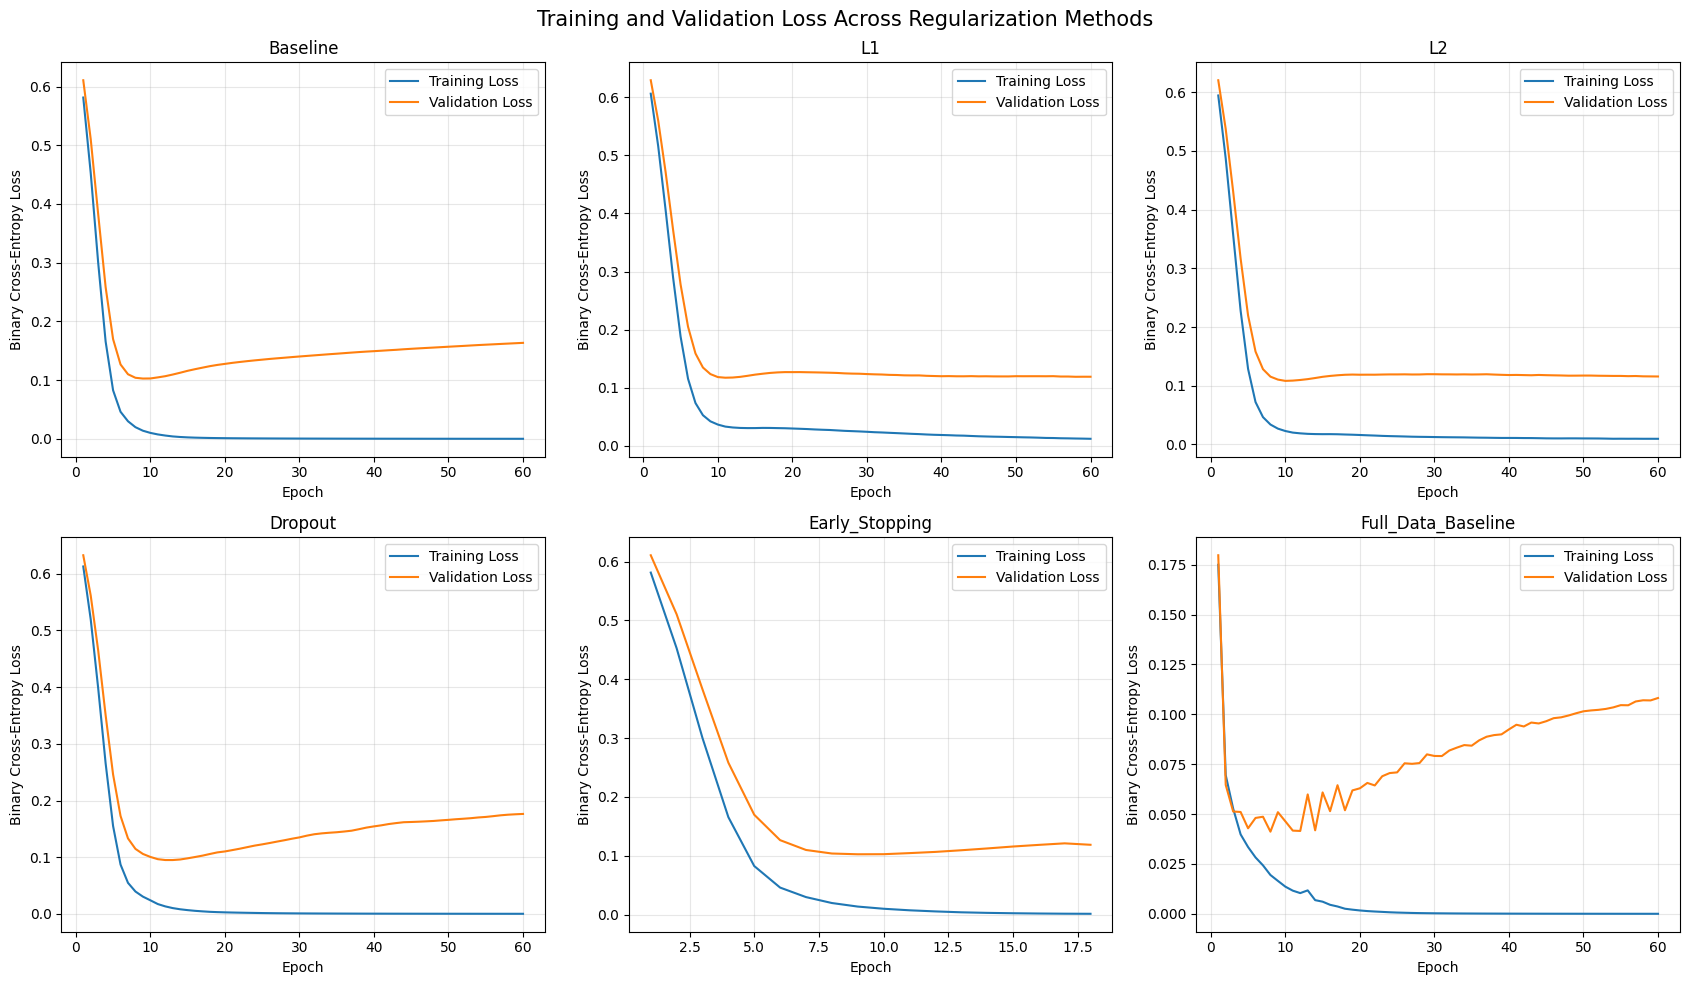

In [ ]:

# ============================================================
# Q3 - CELL 6: LOSS CURVES
# ============================================================

experiment_names = list(EXPERIMENTS.keys())

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

axes = axes.flatten()

for ax, experiment in zip(axes, experiment_names):

    subset = history_df[
        history_df["Experiment"] == experiment
    ]

    grouped = (
        subset
        .groupby("Epoch")
        .agg(
            Train_Mean=("Train_Loss", "mean"),
            Train_Std=("Train_Loss", "std"),
            Val_Mean=("Val_Loss", "mean"),
            Val_Std=("Val_Loss", "std")
        )
        .reset_index()
    )

    ax.plot(
        grouped["Epoch"],
        grouped["Train_Mean"],
        label="Training Loss"
    )

    ax.plot(
        grouped["Epoch"],
        grouped["Val_Mean"],
        label="Validation Loss"
    )

    ax.set_title(experiment)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary Cross-Entropy Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Training and Validation Loss Across Regularization Methods",
    fontsize=15
)

plt.tight_layout()
plt.show()


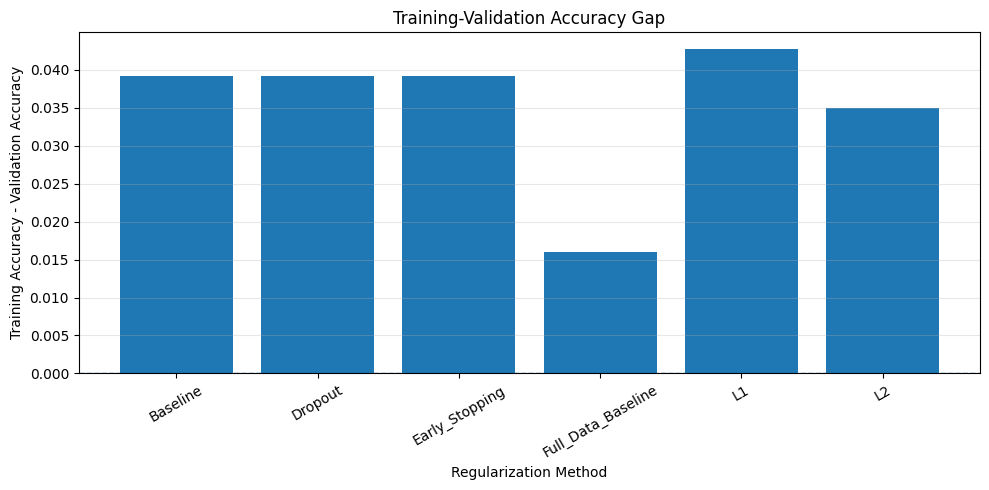

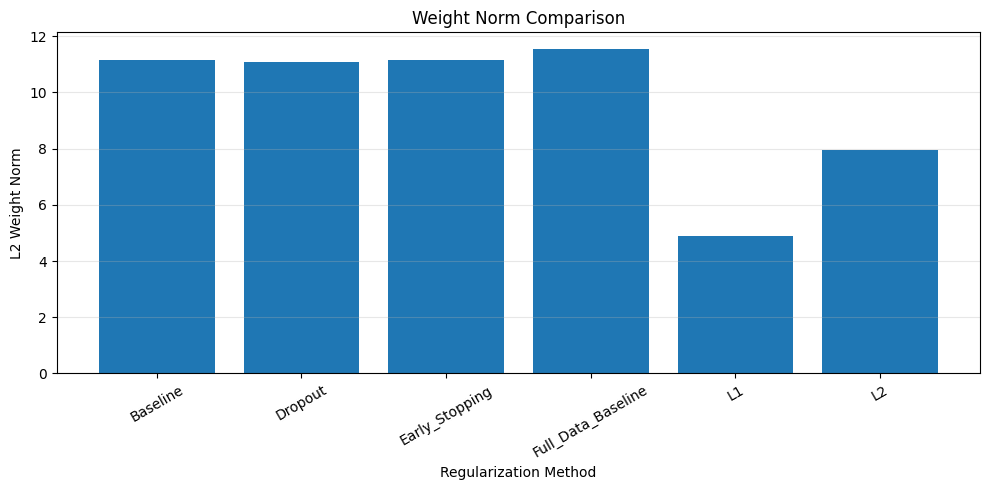

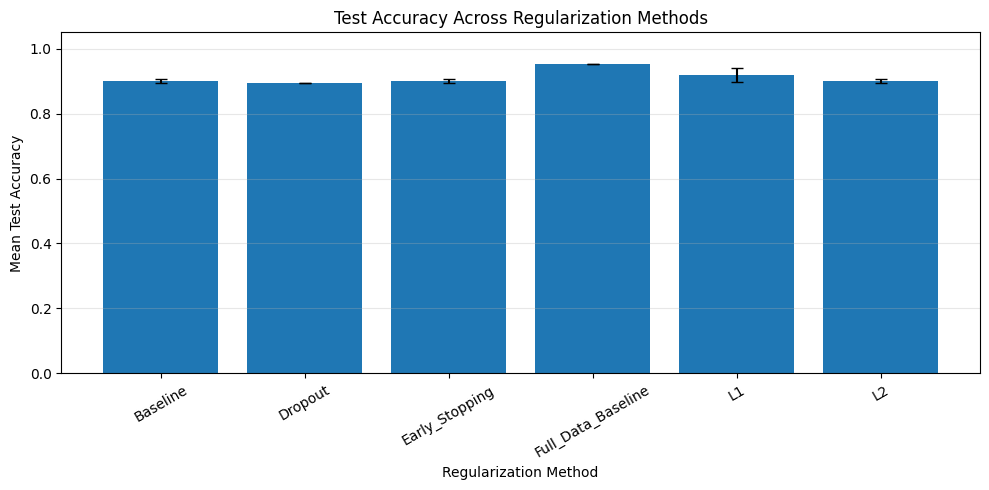

In [ ]:

# ============================================================
# Q3 - CELL 7: GENERALIZATION AND WEIGHT ANALYSIS
# ============================================================

# 1. Accuracy gap
plt.figure(figsize=(10, 5))

plt.bar(
    summary_df["Experiment"],
    summary_df["Accuracy_Gap_Mean"]
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Training-Validation Accuracy Gap")
plt.xlabel("Regularization Method")
plt.ylabel("Training Accuracy - Validation Accuracy")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Weight norms
plt.figure(figsize=(10, 5))

plt.bar(
    summary_df["Experiment"],
    summary_df["Weight_Norm_Mean"]
)

plt.title("Weight Norm Comparison")
plt.xlabel("Regularization Method")
plt.ylabel("L2 Weight Norm")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Test accuracy
plt.figure(figsize=(10, 5))

plt.bar(
    summary_df["Experiment"],
    summary_df["Test_Accuracy_Mean"],
    yerr=summary_df["Test_Accuracy_Std"].fillna(0),
    capsize=4
)

plt.title("Test Accuracy Across Regularization Methods")
plt.xlabel("Regularization Method")
plt.ylabel("Mean Test Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# Q3 - CELL 8: SAVE EXPERIMENTAL EVIDENCE
# ============================================================

from google.colab import files

OUTPUT_DIR = "Q3_Experimental_Evidence"

os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(
    f"{OUTPUT_DIR}/regularization_raw_results.csv",
    index=False
)

history_df.to_csv(
    f"{OUTPUT_DIR}/training_history.csv",
    index=False
)

summary_df.to_csv(
    f"{OUTPUT_DIR}/regularization_summary.csv",
    index=False
)

best_val_loss.to_csv(
    f"{OUTPUT_DIR}/minimum_validation_loss.csv",
    index=False
)

settings = {
    "Dataset": "Wisconsin Breast Cancer Diagnostic",
    "Training_Samples_Full": len(X_train_full),
    "Training_Samples_Small": len(X_train_small),
    "Validation_Samples": len(X_val),
    "Test_Samples": len(X_test),
    "Architecture": [30, 128, 128, 64, 1],
    "Optimizer": "Adam",
    "Learning_Rate": LEARNING_RATE,
    "Batch_Size": BATCH_SIZE,
    "Maximum_Epochs": EPOCHS,
    "Random_Seeds": SEEDS,
    "Experiments": EXPERIMENTS,
    "Device": str(device)
}

with open(
    f"{OUTPUT_DIR}/experiment_settings.json",
    "w"
) as f:

    json.dump(settings, f, indent=4)

zip_filename = "Q3_Experimental_Evidence.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for root, dirs, filenames in os.walk(OUTPUT_DIR):

        for filename in filenames:

            full_path = os.path.join(root, filename)

            archive.write(
                full_path,
                arcname=os.path.relpath(
                    full_path,
                    OUTPUT_DIR
                )
            )

print("Q3 evidence exported.")

for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

files.download(zip_filename)


Q3 evidence exported.
- regularization_raw_results.csv
- experiment_settings.json
- minimum_validation_loss.csv
- training_history.csv
- regularization_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# Q4 - CELL 1: IMPORTS AND DATASET PREPARATION
# ============================================================

import os
import json
import time
import random
import zipfile
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    mean_squared_error,
    mean_absolute_error
)
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

MASTER_SEED = 42
set_seed(MASTER_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Dataset
dataset = load_breast_cancer()

X = dataset.data.astype(np.float32)
y = dataset.target.astype(np.float32)

# 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Fit scaler on training data only
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print("\nDATASET INFORMATION")
print("Dataset:", "Wisconsin Breast Cancer Diagnostic")
print("Total samples:", len(X))
print("Features:", X.shape[1])
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

print("\nDataset preparation completed.")


PyTorch version: 2.14.1+cpu
Device: cpu

DATASET INFORMATION
Dataset: Wisconsin Breast Cancer Diagnostic
Total samples: 569
Features: 30
Training: 398
Validation: 85
Testing: 86

Class distribution:
0.0    212
1.0    357
Name: count, dtype: int64

Dataset preparation completed.


In [ ]:

# ============================================================
# Q4 - CELL 2: MODEL ARCHITECTURE
# ============================================================

class OptimizerNetwork(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(30, 128),
            nn.ReLU(),

            nn.Linear(128, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)

        )

    def forward(self, x):
        return self.network(x)


# Create one sample model
sample_model = OptimizerNetwork()

parameter_count = sum(
    p.numel()
    for p in sample_model.parameters()
    if p.requires_grad
)

print("Architecture: 30 -> 128 -> 128 -> 64 -> 1")
print("Trainable parameters:", parameter_count)

print("\nModel summary:")
print(sample_model)


Architecture: 30 -> 128 -> 128 -> 64 -> 1
Trainable parameters: 28801

Model summary:
OptimizerNetwork(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [ ]:

# ============================================================
# Q4 - CELL 3: OPTIMIZER CONFIGURATIONS
# ============================================================

BASE_LR = 0.001

OPTIMIZER_CONFIGS = {

    "SGD": {
        "type": "SGD",
        "lr": BASE_LR
    },

    "Momentum": {
        "type": "Momentum",
        "lr": BASE_LR,
        "momentum": 0.9
    },

    "RMSProp": {
        "type": "RMSProp",
        "lr": BASE_LR,
        "alpha": 0.99
    },

    "Adam": {
        "type": "Adam",
        "lr": BASE_LR
    }

}

def create_optimizer(model, config):

    optimizer_type = config["type"]

    if optimizer_type == "SGD":

        return torch.optim.SGD(
            model.parameters(),
            lr=config["lr"]
        )

    elif optimizer_type == "Momentum":

        return torch.optim.SGD(
            model.parameters(),
            lr=config["lr"],
            momentum=config["momentum"]
        )

    elif optimizer_type == "RMSProp":

        return torch.optim.RMSprop(
            model.parameters(),
            lr=config["lr"],
            alpha=config["alpha"]
        )

    elif optimizer_type == "Adam":

        return torch.optim.Adam(
            model.parameters(),
            lr=config["lr"]
        )

    else:
        raise ValueError("Unknown optimizer")


print("Optimizer configurations:")

for name, config in OPTIMIZER_CONFIGS.items():
    print(name, ":", config)


Optimizer configurations:
SGD : {'type': 'SGD', 'lr': 0.001}
Momentum : {'type': 'Momentum', 'lr': 0.001, 'momentum': 0.9}
RMSProp : {'type': 'RMSProp', 'lr': 0.001, 'alpha': 0.99}
Adam : {'type': 'Adam', 'lr': 0.001}


In [ ]:

# ============================================================
# Q4 - CELL 4: TRAINING AND EVALUATION FUNCTIONS
# ============================================================

BATCH_SIZE = 32
EPOCHS = 60
SEEDS = [42, 123, 2026]
TARGET_VAL_LOSS = 0.15

criterion = nn.BCEWithLogitsLoss()


def make_loader(X_data, y_data, shuffle=False, seed=42):

    dataset = TensorDataset(
        torch.tensor(X_data, dtype=torch.float32),
        torch.tensor(y_data, dtype=torch.float32).reshape(-1, 1)
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator if shuffle else None
    )


def evaluate_model(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    probabilities = []
    actual = []

    with torch.no_grad():

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * len(xb)
            total_samples += len(xb)

            probs = torch.sigmoid(logits)

            probabilities.extend(
                probs.cpu().numpy().flatten()
            )

            actual.extend(
                yb.cpu().numpy().flatten()
            )

    probabilities = np.array(probabilities)
    actual = np.array(actual)

    predictions = (probabilities >= 0.5).astype(int)

    return {

        "loss": total_loss / total_samples,

        "accuracy": accuracy_score(
            actual, predictions
        ),

        "precision": precision_score(
            actual, predictions,
            zero_division=0
        ),

        "recall": recall_score(
            actual, predictions,
            zero_division=0
        ),

        "rmse": np.sqrt(
            mean_squared_error(actual, probabilities)
        ),

        "mae": mean_absolute_error(
            actual, probabilities
        )

    }


def run_experiment(
    optimizer_name,
    optimizer_config,
    seed,
    initial_state
):

    # Same starting weights for every optimizer
    model = OptimizerNetwork().to(device)

    model.load_state_dict(
        copy.deepcopy(initial_state)
    )

    optimizer = create_optimizer(
        model,
        optimizer_config
    )

    train_loader = make_loader(
        X_train, y_train, True, seed
    )

    train_eval_loader = make_loader(
        X_train, y_train
    )

    val_loader = make_loader(
        X_val, y_val
    )

    test_loader = make_loader(
        X_test, y_test
    )

    history = []

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0

    convergence_epoch = None

    start = time.time()

    for epoch in range(EPOCHS):

        model.train()

        for xb, yb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)

            loss = criterion(logits, yb)

            loss.backward()

            optimizer.step()

        # Evaluate after each epoch
        train_metrics = evaluate_model(
            model, train_eval_loader
        )

        val_metrics = evaluate_model(
            model, val_loader
        )

        history.append({

            "Optimizer": optimizer_name,
            "Seed": seed,
            "Epoch": epoch + 1,

            "Train_Loss": train_metrics["loss"],
            "Val_Loss": val_metrics["loss"],

            "Train_Accuracy": train_metrics["accuracy"],
            "Val_Accuracy": val_metrics["accuracy"]

        })

        # Record first epoch reaching target
        if (
            convergence_epoch is None
            and val_metrics["loss"] <= TARGET_VAL_LOSS
        ):
            convergence_epoch = epoch + 1

        # Save best validation checkpoint
        if val_metrics["loss"] < best_val_loss:

            best_val_loss = val_metrics["loss"]

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            best_epoch = epoch + 1

    elapsed = time.time() - start

    # Restore best validation checkpoint
    model.load_state_dict(best_state)

    train_final = evaluate_model(
        model, train_eval_loader
    )

    val_final = evaluate_model(
        model, val_loader
    )

    test_final = evaluate_model(
        model, test_loader
    )

    result = {

        "Optimizer": optimizer_name,
        "Seed": seed,

        "Learning_Rate": optimizer_config["lr"],

        "Best_Epoch": best_epoch,

        "Convergence_Epoch": (
            convergence_epoch
            if convergence_epoch is not None
            else np.nan
        ),

        "Best_Val_Loss": best_val_loss,

        "Train_Loss": train_final["loss"],
        "Val_Accuracy": val_final["accuracy"],

        "Test_Loss": test_final["loss"],
        "Test_Accuracy": test_final["accuracy"],
        "Test_Precision": test_final["precision"],
        "Test_Recall": test_final["recall"],

        "Test_RMSE": test_final["rmse"],
        "Test_MAE": test_final["mae"],

        "Training_Time_Seconds": elapsed

    }

    return result, history


print("Training and evaluation functions defined.")


Training and evaluation functions defined.


In [ ]:

# ============================================================
# Q4 - CELL 5: MAIN OPTIMIZER COMPARISON
# ============================================================

main_results = []
main_histories = []

start_time = time.time()

for seed in SEEDS:

    print("\n" + "=" * 70)
    print("RANDOM SEED:", seed)
    print("=" * 70)

    set_seed(seed)

    # Generate one initial state for this seed
    reference_model = OptimizerNetwork()

    initial_state = copy.deepcopy(
        reference_model.state_dict()
    )

    for optimizer_name, config in OPTIMIZER_CONFIGS.items():

        print("\nRunning:", optimizer_name)

        result, history = run_experiment(
            optimizer_name,
            config,
            seed,
            initial_state
        )

        main_results.append(result)
        main_histories.extend(history)

        print(
            "Best validation loss:",
            round(result["Best_Val_Loss"], 5)
        )

        print(
            "Test accuracy:",
            round(result["Test_Accuracy"], 4)
        )

        print(
            "Training time:",
            round(result["Training_Time_Seconds"], 2),
            "seconds"
        )


main_results_df = pd.DataFrame(main_results)
main_history_df = pd.DataFrame(main_histories)

print("\n" + "=" * 70)
print("PRIMARY OPTIMIZER EXPERIMENT COMPLETED")
print("=" * 70)

print("Total training runs:", len(main_results_df))
print("Total epoch records:", len(main_history_df))
print(
    "Total execution time:",
    round(time.time() - start_time, 2),
    "seconds"
)

display(main_results_df)



RANDOM SEED: 42

Running: SGD
Best validation loss: 0.65377
Test accuracy: 0.6977
Training time: 2.71 seconds

Running: Momentum
Best validation loss: 0.08389
Test accuracy: 0.9302
Training time: 2.49 seconds

Running: RMSProp
Best validation loss: 0.03343
Test accuracy: 0.9535
Training time: 2.73 seconds

Running: Adam
Best validation loss: 0.03947
Test accuracy: 0.9535
Training time: 3.27 seconds

RANDOM SEED: 123

Running: SGD
Best validation loss: 0.61386
Test accuracy: 0.814
Training time: 3.11 seconds

Running: Momentum
Best validation loss: 0.07881
Test accuracy: 0.8953
Training time: 2.49 seconds

Running: RMSProp
Best validation loss: 0.03336
Test accuracy: 0.9535
Training time: 2.69 seconds

Running: Adam
Best validation loss: 0.03956
Test accuracy: 0.9535
Training time: 2.92 seconds

RANDOM SEED: 2026

Running: SGD
Best validation loss: 0.65513
Test accuracy: 0.6279
Training time: 2.92 seconds

Running: Momentum
Best validation loss: 0.08662
Test accuracy: 0.9419
Training t

,Optimizer,Seed,Learning_Rate,Best_Epoch,Convergence_Epoch,Best_Val_Loss,Train_Loss,Val_Accuracy,Test_Loss,Test_Accuracy,Test_Precision,Test_Recall,Test_RMSE,Test_MAE,Training_Time_Seconds
0,SGD,42,0.001,60,NaN,0.653771,0.652332,0.658824,0.650365,0.697674,0.675000,1.000000,0.478207,0.477118,2.707494
1,Momentum,42,0.001,60,42.0,0.083891,0.084643,0.988235,0.141013,0.930233,0.913793,0.981481,0.207825,0.099192,2.487138
2,RMSProp,42,0.001,4,1.0,0.033426,0.032190,0.976471,0.119808,0.953488,0.946429,0.981481,0.188957,0.063704,2.729906
3,Adam,42,0.001,11,2.0,0.039471,0.022837,0.976471,0.106610,0.953488,0.962963,0.962963,0.177069,0.050154,3.267776
4,SGD,123,0.001,60,NaN,0.613862,0.607338,0.741176,0.605654,0.813953,0.771429,1.000000,0.454611,0.452213,3.105032
5,Momentum,123,0.001,60,35.0,0.078807,0.083804,0.988235,0.128612,0.895349,0.881356,0.962963,0.200094,0.096206,2.487767
6,RMSProp,123,0.001,2,1.0,0.033357,0.049839,0.976471,0.121745,0.953488,0.962963,0.962963,0.187343,0.063945,2.685188
7,Adam,123,0.001,5,2.0,0.039557,0.045683,0.976471,0.109290,0.953488,0.962963,0.962963,0.187569,0.071795,2.915351
8,SGD,2026,0.001,60,NaN,0.655127,0.650375,0.623529,0.651650,0.627907,0.627907,1.000000,0.478976,0.476047,2.919601
9,Momentum,2026,0.001,60,43.0,0.086619,0.090418,0.988235,0.151288,0.941860,0.915254,1.000000,0.215825,0.105288,3.139592


In [ ]:

# ============================================================
# Q4 - CELL 6: LEARNING RATE SENSITIVITY
# ============================================================

LEARNING_RATES = [0.0001, 0.001, 0.01]

lr_results = []
lr_histories = []

for optimizer_name in ["SGD", "Adam"]:

    for lr in LEARNING_RATES:

        config = {
            "type": optimizer_name,
            "lr": lr
        }

        print("\n" + "=" * 65)
        print(
            "Optimizer:", optimizer_name,
            "| Learning rate:", lr
        )

        for seed in SEEDS:

            set_seed(seed)

            reference_model = OptimizerNetwork()

            initial_state = copy.deepcopy(
                reference_model.state_dict()
            )

            result, history = run_experiment(
                optimizer_name,
                config,
                seed,
                initial_state
            )

            result["Experiment"] = "Learning_Rate_Sensitivity"

            lr_results.append(result)
            lr_histories.extend(history)

            print(
                "Seed:", seed,
                "| Best val loss:",
                round(result["Best_Val_Loss"], 5)
            )


lr_results_df = pd.DataFrame(lr_results)
lr_history_df = pd.DataFrame(lr_histories)

print("\nLearning-rate experiments completed.")
print("Additional runs:", len(lr_results_df))

display(lr_results_df)



Optimizer: SGD | Learning rate: 0.0001
Seed: 42 | Best val loss: 0.68731
Seed: 123 | Best val loss: 0.6687
Seed: 2026 | Best val loss: 0.68519

Optimizer: SGD | Learning rate: 0.001
Seed: 42 | Best val loss: 0.65377
Seed: 123 | Best val loss: 0.61386
Seed: 2026 | Best val loss: 0.65513

Optimizer: SGD | Learning rate: 0.01
Seed: 42 | Best val loss: 0.0827
Seed: 123 | Best val loss: 0.07766
Seed: 2026 | Best val loss: 0.08481

Optimizer: Adam | Learning rate: 0.0001
Seed: 42 | Best val loss: 0.04781
Seed: 123 | Best val loss: 0.04308
Seed: 2026 | Best val loss: 0.04353

Optimizer: Adam | Learning rate: 0.001
Seed: 42 | Best val loss: 0.03947
Seed: 123 | Best val loss: 0.03956
Seed: 2026 | Best val loss: 0.01472

Optimizer: Adam | Learning rate: 0.01
Seed: 42 | Best val loss: 0.03714
Seed: 123 | Best val loss: 0.02809
Seed: 2026 | Best val loss: 0.04202

Learning-rate experiments completed.
Additional runs: 18


,Optimizer,Seed,Learning_Rate,Best_Epoch,Convergence_Epoch,Best_Val_Loss,Train_Loss,Val_Accuracy,Test_Loss,Test_Accuracy,Test_Precision,Test_Recall,Test_RMSE,Test_MAE,Training_Time_Seconds,Experiment
0,SGD,42,0.0001,60,NaN,0.687306,0.688425,0.588235,0.684857,0.651163,0.650000,0.962963,0.495839,0.495692,7.470355,Learning_Rate_Sensitivity
1,SGD,123,0.0001,60,NaN,0.668696,0.666357,0.647059,0.665753,0.674419,0.658537,1.000000,0.486134,0.485703,5.880012,Learning_Rate_Sensitivity
2,SGD,2026,0.0001,60,NaN,0.685188,0.684037,0.623529,0.683669,0.627907,0.627907,1.000000,0.495235,0.494104,4.525589,Learning_Rate_Sensitivity
3,SGD,42,0.0010,60,NaN,0.653771,0.652332,0.658824,0.650365,0.697674,0.675000,1.000000,0.478207,0.477118,6.310805,Learning_Rate_Sensitivity
4,SGD,123,0.0010,60,NaN,0.613862,0.607338,0.741176,0.605654,0.813953,0.771429,1.000000,0.454611,0.452213,2.499725,Learning_Rate_Sensitivity
5,SGD,2026,0.0010,60,NaN,0.655127,0.650375,0.623529,0.651650,0.627907,0.627907,1.000000,0.478976,0.476047,2.392359,Learning_Rate_Sensitivity
6,SGD,42,0.0100,60,40.0,0.082700,0.083076,0.988235,0.139546,0.930233,0.913793,0.981481,0.206556,0.098301,2.533495,Learning_Rate_Sensitivity
7,SGD,123,0.0100,60,34.0,0.077657,0.082752,0.988235,0.127924,0.895349,0.881356,0.962963,0.199582,0.095638,2.597792,Learning_Rate_Sensitivity
8,SGD,2026,0.0100,60,42.0,0.084811,0.088146,0.988235,0.149045,0.941860,0.915254,1.000000,0.214095,0.103960,3.446843,Learning_Rate_Sensitivity
9,Adam,42,0.0001,60,16.0,0.047807,0.033750,0.976471,0.109431,0.965116,0.963636,0.981481,0.184449,0.063542,2.986323,Learning_Rate_Sensitivity


In [ ]:

# ============================================================
# Q4 - CELL 7: STATISTICAL RESULTS
# ============================================================

summary_df = (
    main_results_df
    .groupby("Optimizer")
    .agg(
        Best_Val_Loss_Mean=("Best_Val_Loss", "mean"),
        Best_Val_Loss_Std=("Best_Val_Loss", "std"),

        Test_Accuracy_Mean=("Test_Accuracy", "mean"),
        Test_Accuracy_Std=("Test_Accuracy", "std"),

        Test_Precision_Mean=("Test_Precision", "mean"),
        Test_Recall_Mean=("Test_Recall", "mean"),

        Test_RMSE_Mean=("Test_RMSE", "mean"),
        Test_MAE_Mean=("Test_MAE", "mean"),

        Convergence_Epoch_Mean=("Convergence_Epoch", "mean"),

        Training_Time_Mean=("Training_Time_Seconds", "mean")
    )
    .reset_index()
    .round(5)
)

print("=" * 80)
print("PRIMARY OPTIMIZER COMPARISON")
print("=" * 80)

display(summary_df)


# Learning rate sensitivity summary
lr_summary_df = (
    lr_results_df
    .groupby(["Optimizer", "Learning_Rate"])
    .agg(
        Best_Val_Loss_Mean=("Best_Val_Loss", "mean"),
        Best_Val_Loss_Std=("Best_Val_Loss", "std"),

        Test_Accuracy_Mean=("Test_Accuracy", "mean"),
        Test_Accuracy_Std=("Test_Accuracy", "std"),

        Convergence_Epoch_Mean=("Convergence_Epoch", "mean"),
        Training_Time_Mean=("Training_Time_Seconds", "mean")
    )
    .reset_index()
    .round(5)
)

print("\nLEARNING RATE SENSITIVITY")
display(lr_summary_df)


# Individual run comparison
print("\nINDIVIDUAL PRIMARY RUNS")
display(main_results_df.round(5))


PRIMARY OPTIMIZER COMPARISON


,Optimizer,Best_Val_Loss_Mean,Best_Val_Loss_Std,Test_Accuracy_Mean,Test_Accuracy_Std,Test_Precision_Mean,Test_Recall_Mean,Test_RMSE_Mean,Test_MAE_Mean,Convergence_Epoch_Mean,Training_Time_Mean
0,Adam,0.03125,0.01432,0.95349,0.00000,0.96296,0.96296,0.18100,0.05470,2.0,3.04072
1,Momentum,0.08311,0.00396,0.92248,0.02421,0.90347,0.98148,0.20791,0.10023,40.0,2.70483
2,RMSProp,0.03482,0.00247,0.95736,0.00671,0.96351,0.96914,0.17874,0.05483,1.0,2.72142
3,SGD,0.64092,0.02344,0.71318,0.09399,0.69145,1.00000,0.47060,0.46846,NaN,2.91071



LEARNING RATE SENSITIVITY


,Optimizer,Learning_Rate,Best_Val_Loss_Mean,Best_Val_Loss_Std,Test_Accuracy_Mean,Test_Accuracy_Std,Convergence_Epoch_Mean,Training_Time_Mean
0,Adam,0.0001,0.04480,0.00261,0.95736,0.00671,15.66667,2.98330
1,Adam,0.0010,0.03125,0.01432,0.95349,0.00000,2.00000,3.38894
2,Adam,0.0100,0.03575,0.00707,0.95736,0.01343,1.33333,3.43984
3,SGD,0.0001,0.68040,0.01019,0.65116,0.02326,NaN,5.95865
4,SGD,0.0010,0.64092,0.02344,0.71318,0.09399,NaN,3.73430
5,SGD,0.0100,0.08172,0.00368,0.92248,0.02421,38.66667,2.85938



INDIVIDUAL PRIMARY RUNS


,Optimizer,Seed,Learning_Rate,Best_Epoch,Convergence_Epoch,Best_Val_Loss,Train_Loss,Val_Accuracy,Test_Loss,Test_Accuracy,Test_Precision,Test_Recall,Test_RMSE,Test_MAE,Training_Time_Seconds
0,SGD,42,0.001,60,NaN,0.65377,0.65233,0.65882,0.65037,0.69767,0.67500,1.00000,0.47821,0.47712,2.70749
1,Momentum,42,0.001,60,42.0,0.08389,0.08464,0.98824,0.14101,0.93023,0.91379,0.98148,0.20783,0.09919,2.48714
2,RMSProp,42,0.001,4,1.0,0.03343,0.03219,0.97647,0.11981,0.95349,0.94643,0.98148,0.18896,0.06370,2.72991
3,Adam,42,0.001,11,2.0,0.03947,0.02284,0.97647,0.10661,0.95349,0.96296,0.96296,0.17707,0.05015,3.26778
4,SGD,123,0.001,60,NaN,0.61386,0.60734,0.74118,0.60565,0.81395,0.77143,1.00000,0.45461,0.45221,3.10503
5,Momentum,123,0.001,60,35.0,0.07881,0.08380,0.98824,0.12861,0.89535,0.88136,0.96296,0.20009,0.09621,2.48777
6,RMSProp,123,0.001,2,1.0,0.03336,0.04984,0.97647,0.12174,0.95349,0.96296,0.96296,0.18734,0.06395,2.68519
7,Adam,123,0.001,5,2.0,0.03956,0.04568,0.97647,0.10929,0.95349,0.96296,0.96296,0.18757,0.07179,2.91535
8,SGD,2026,0.001,60,NaN,0.65513,0.65037,0.62353,0.65165,0.62791,0.62791,1.00000,0.47898,0.47605,2.91960
9,Momentum,2026,0.001,60,43.0,0.08662,0.09042,0.98824,0.15129,0.94186,0.91525,1.00000,0.21582,0.10529,3.13959


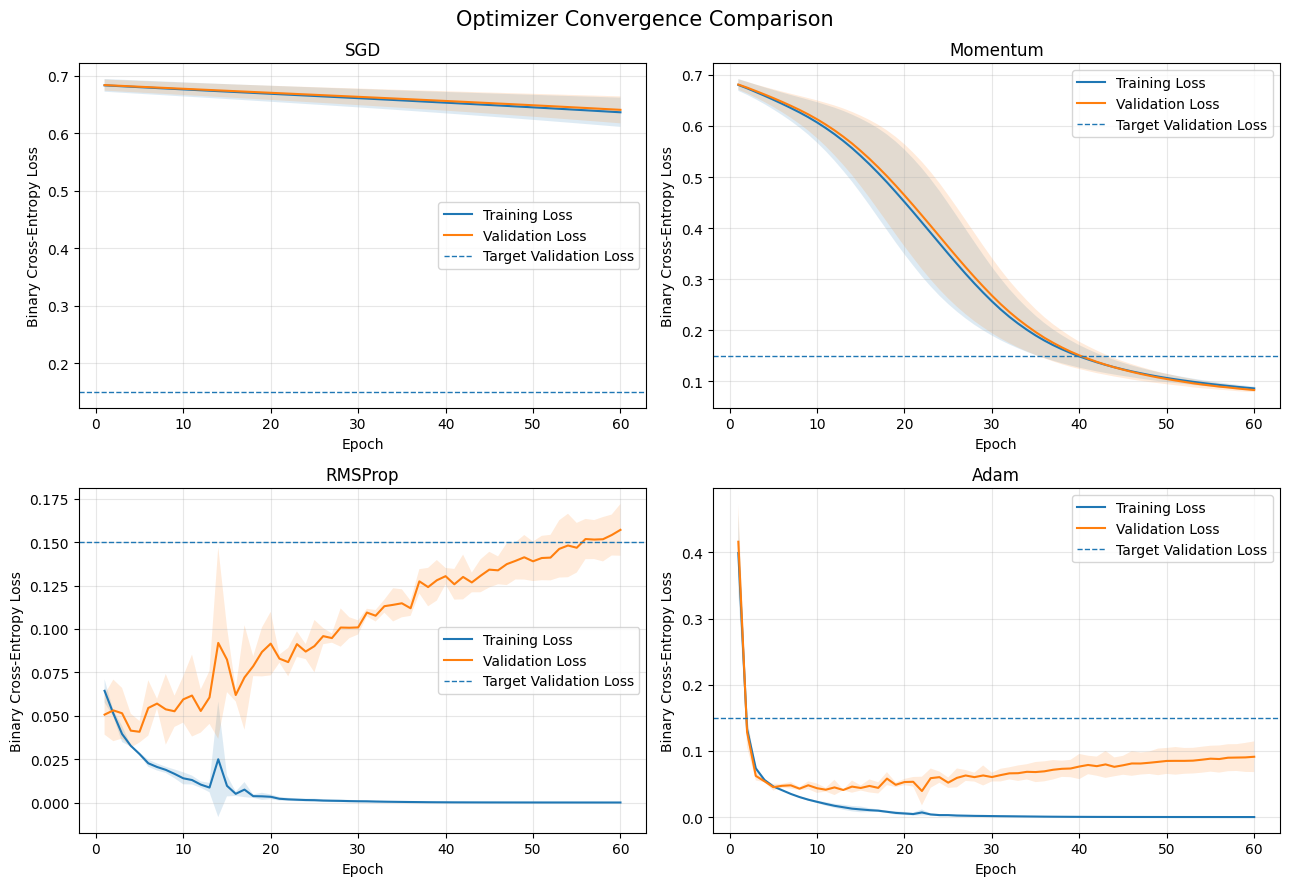

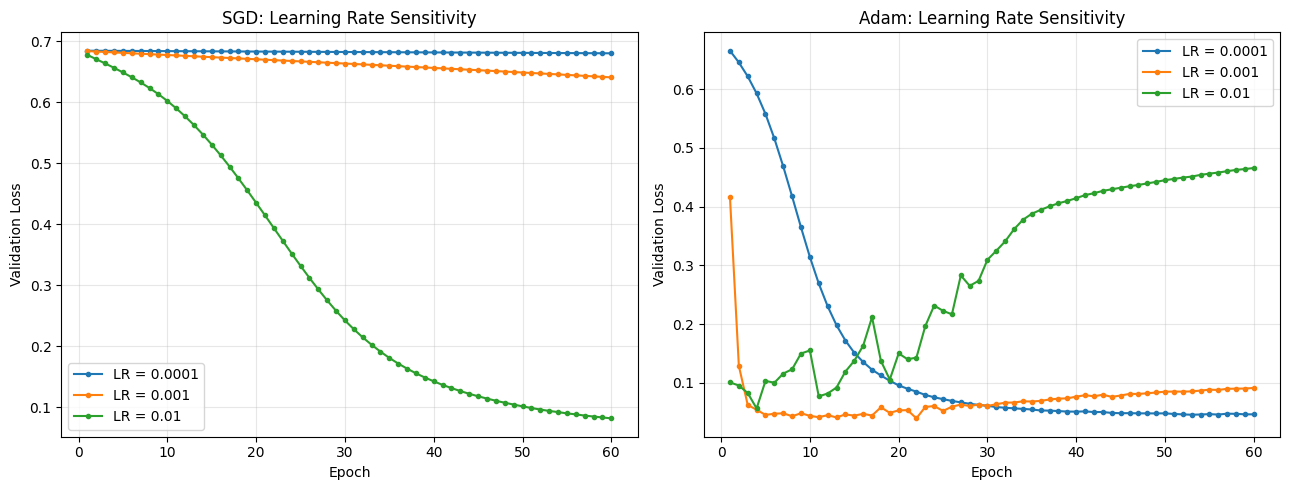

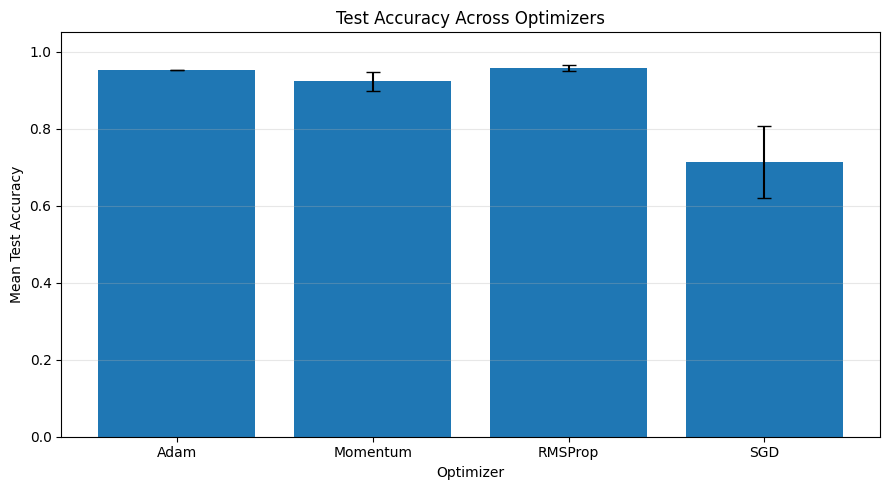

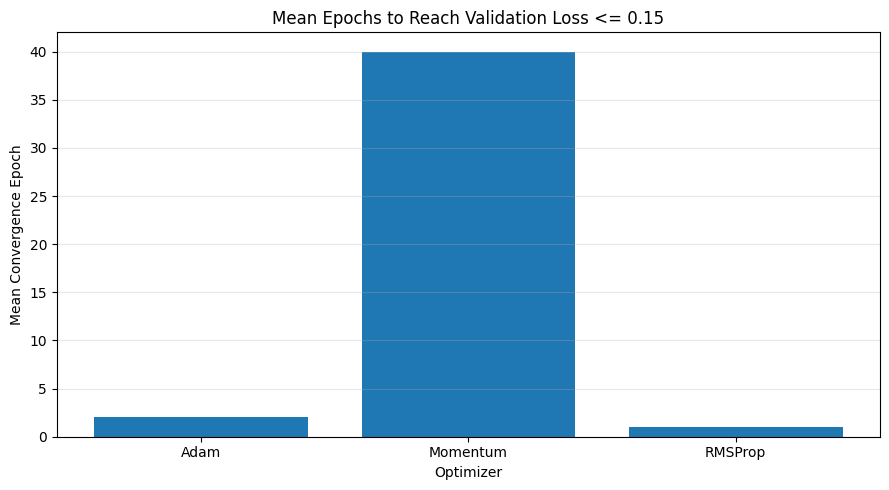

In [ ]:

# ============================================================
# Q4 - CELL 8: CONVERGENCE VISUALISATIONS
# ============================================================

# ------------------------------------------------------------
# GRAPH 1: PRIMARY OPTIMIZER LOSS CURVES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

axes = axes.flatten()

for ax, optimizer_name in zip(
    axes,
    OPTIMIZER_CONFIGS.keys()
):

    subset = main_history_df[
        main_history_df["Optimizer"] == optimizer_name
    ]

    grouped = (
        subset
        .groupby("Epoch")
        .agg(
            Train_Mean=("Train_Loss", "mean"),
            Train_Std=("Train_Loss", "std"),
            Val_Mean=("Val_Loss", "mean"),
            Val_Std=("Val_Loss", "std")
        )
        .reset_index()
    )

    ax.plot(
        grouped["Epoch"],
        grouped["Train_Mean"],
        label="Training Loss"
    )

    ax.fill_between(
        grouped["Epoch"],
        grouped["Train_Mean"] - grouped["Train_Std"].fillna(0),
        grouped["Train_Mean"] + grouped["Train_Std"].fillna(0),
        alpha=0.15
    )

    ax.plot(
        grouped["Epoch"],
        grouped["Val_Mean"],
        label="Validation Loss"
    )

    ax.fill_between(
        grouped["Epoch"],
        grouped["Val_Mean"] - grouped["Val_Std"].fillna(0),
        grouped["Val_Mean"] + grouped["Val_Std"].fillna(0),
        alpha=0.15
    )

    ax.axhline(
        TARGET_VAL_LOSS,
        linestyle="--",
        linewidth=1,
        label="Target Validation Loss"
    )

    ax.set_title(optimizer_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary Cross-Entropy Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Optimizer Convergence Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 2: LEARNING RATE SENSITIVITY
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

for ax, optimizer_name in zip(
    axes,
    ["SGD", "Adam"]
):

    subset = lr_history_df[
        lr_history_df["Optimizer"] == optimizer_name
    ]

    for lr in LEARNING_RATES:

        part = subset[
            subset["Seed"].isin(SEEDS)
        ]

        # Identify histories by their corresponding
        # learning-rate experiment order.
        # Each rate has three consecutive runs.
        run_index = (
            LEARNING_RATES.index(lr) * len(SEEDS)
        )

        rate_histories = lr_history_df[
            lr_history_df["Optimizer"] == optimizer_name
        ]

        # Use the matching result rows and seeds to
        # recover the learning-rate group.
        rate_result = lr_results_df[
            (lr_results_df["Optimizer"] == optimizer_name) &
            (lr_results_df["Learning_Rate"] == lr)
        ]

        # The history records are stored in experiment order.
        start = run_index * EPOCHS
        end = start + len(SEEDS) * EPOCHS

        ordered = rate_histories.iloc[start:end]

        grouped = (
            ordered
            .groupby("Epoch")["Val_Loss"]
            .mean()
        )

        ax.plot(
            grouped.index,
            grouped.values,
            marker=".",
            label=f"LR = {lr}"
        )

    ax.set_title(f"{optimizer_name}: Learning Rate Sensitivity")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Validation Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 3: TEST ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    summary_df["Optimizer"],
    summary_df["Test_Accuracy_Mean"],
    yerr=summary_df["Test_Accuracy_Std"],
    capsize=5
)

plt.title("Test Accuracy Across Optimizers")
plt.xlabel("Optimizer")
plt.ylabel("Mean Test Accuracy")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 4: CONVERGENCE EPOCHS
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    summary_df["Optimizer"],
    summary_df["Convergence_Epoch_Mean"]
)

plt.title(
    f"Mean Epochs to Reach Validation Loss <= {TARGET_VAL_LOSS}"
)

plt.xlabel("Optimizer")
plt.ylabel("Mean Convergence Epoch")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# Q4 - CELL 9: EXPORT ALL EXPERIMENTAL EVIDENCE
# ============================================================

from google.colab import files

OUTPUT_DIR = "Q4_Experimental_Evidence"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Main optimizer results
main_results_df.to_csv(
    f"{OUTPUT_DIR}/main_optimizer_results.csv",
    index=False
)

main_history_df.to_csv(
    f"{OUTPUT_DIR}/main_training_history.csv",
    index=False
)

summary_df.to_csv(
    f"{OUTPUT_DIR}/optimizer_summary.csv",
    index=False
)

# Learning rate results
lr_results_df.to_csv(
    f"{OUTPUT_DIR}/learning_rate_results.csv",
    index=False
)

lr_history_df.to_csv(
    f"{OUTPUT_DIR}/learning_rate_history.csv",
    index=False
)

lr_summary_df.to_csv(
    f"{OUTPUT_DIR}/learning_rate_summary.csv",
    index=False
)

# Experiment settings
settings = {

    "Dataset": "Wisconsin Breast Cancer Diagnostic",

    "Dataset_Samples": len(X),
    "Input_Features": X.shape[1],

    "Training_Samples": len(X_train),
    "Validation_Samples": len(X_val),
    "Test_Samples": len(X_test),

    "Architecture": [30, 128, 128, 64, 1],

    "Activation": "ReLU",
    "Loss": "BCEWithLogitsLoss",

    "Batch_Size": BATCH_SIZE,
    "Maximum_Epochs": EPOCHS,

    "Random_Seeds": SEEDS,

    "Main_Learning_Rate": BASE_LR,

    "Optimizers": list(OPTIMIZER_CONFIGS.keys()),

    "Learning_Rates_Tested": LEARNING_RATES,

    "Convergence_Target_Validation_Loss": TARGET_VAL_LOSS,

    "Device": str(device)

}

with open(
    f"{OUTPUT_DIR}/experiment_settings.json",
    "w"
) as f:

    json.dump(settings, f, indent=4)


# Create ZIP archive
zip_filename = "Q4_Experimental_Evidence.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for root, dirs, filenames in os.walk(OUTPUT_DIR):

        for filename in filenames:

            full_path = os.path.join(root, filename)

            archive.write(
                full_path,
                arcname=os.path.relpath(
                    full_path,
                    OUTPUT_DIR
                )
            )

print("=" * 60)
print("Q4 EVIDENCE EXPORTED SUCCESSFULLY")
print("=" * 60)

for filename in os.listdir(OUTPUT_DIR):
    print("-", filename)

print("\nDownloading evidence ZIP...")

files.download(zip_filename)


Q4 EVIDENCE EXPORTED SUCCESSFULLY
- main_optimizer_results.csv
- learning_rate_results.csv
- experiment_settings.json
- learning_rate_summary.csv
- main_training_history.csv
- learning_rate_history.csv
- optimizer_summary.csv



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: cpu


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 198kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.71MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 2.77MB/s]



DATASET INFORMATION
Training samples: 60000
Testing samples: 10000
Image dimensions: torch.Size([1, 28, 28])
Number of classes: 10


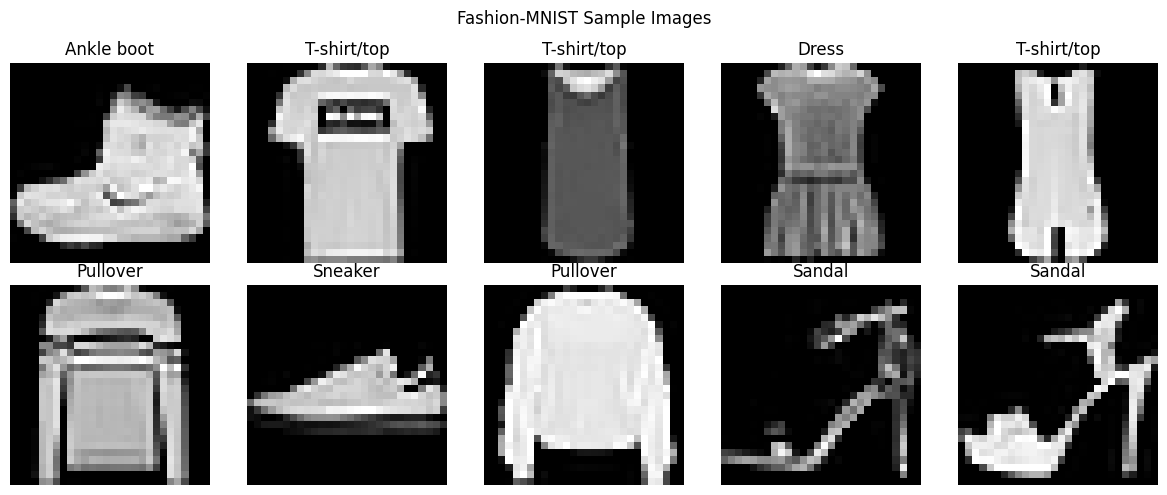

In [ ]:

# ============================================================
# Q5 - CELL 1: LIBRARIES AND DATASET
# ============================================================

import os
import json
import time
import copy
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, Subset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

MASTER_SEED = 42
set_seed(MASTER_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("\nDATASET INFORMATION")
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Image dimensions:", train_dataset[0][0].shape)
print("Number of classes:", len(CLASS_NAMES))


# ------------------------------------------------------------
# DATASET VISUALISATION
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    image, label = train_dataset[i]

    ax.imshow(
        image.squeeze(),
        cmap="gray"
    )

    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")

plt.suptitle("Fashion-MNIST Sample Images")
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# Q5 - CELL 2: DATA LOADERS
# ============================================================

BATCH_SIZE = 128

def create_loaders(seed):

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, test_loader


train_loader, test_loader = create_loaders(42)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Batch size: 128
Training batches: 469
Testing batches: 79
Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])


In [ ]:

# ============================================================
# Q5 - CELL 3: CNN ARCHITECTURES
# ============================================================

class CNN_A(nn.Module):
    """
    One convolutional block.
    """

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2)

        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(16 * 14 * 14, 128),
            nn.ReLU(),

            nn.Linear(128, 10)

        )

    def forward(self, x):

        x = self.features(x)

        return self.classifier(x)


class CNN_B(nn.Module):
    """
    Two convolutional blocks.
    """

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)

        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),

            nn.Linear(128, 10)

        )

    def forward(self, x):

        x = self.features(x)

        return self.classifier(x)


class CNN_C(nn.Module):
    """
    Three convolutional blocks with global average pooling.
    """

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU()

        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Linear(128, 10)

    def forward(self, x):

        x = self.features(x)

        x = self.pool(x)

        x = torch.flatten(x, 1)

        return self.classifier(x)


MODELS = {
    "CNN_A": CNN_A,
    "CNN_B": CNN_B,
    "CNN_C": CNN_C
}

print("Three CNN architectures defined successfully.")


Three CNN architectures defined successfully.


In [ ]:

# ============================================================
# Q5 - CELL 4: MODEL COMPLEXITY
# ============================================================

complexity_records = []

for model_name, model_class in MODELS.items():

    model = model_class()

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    complexity_records.append({

        "Architecture": model_name,

        "Total_Parameters": total_params,

        "Trainable_Parameters": trainable_params,

        "Parameter_Memory_MB":
            trainable_params * 4 / (1024 ** 2)

    })

complexity_df = pd.DataFrame(complexity_records)

print("CNN ARCHITECTURE COMPLEXITY")
display(complexity_df)


CNN ARCHITECTURE COMPLEXITY


,Architecture,Total_Parameters,Trainable_Parameters,Parameter_Memory_MB
0,CNN_A,402986,402986,1.537270
1,CNN_B,421642,421642,1.608437
2,CNN_C,93962,93962,0.358437


In [ ]:

# ============================================================
# Q5 - CELL 5: TRAINING AND EVALUATION FUNCTIONS
# ============================================================

LEARNING_RATE = 0.001
EPOCHS = 10
SEEDS = [42, 123, 2026]

criterion = nn.CrossEntropyLoss()


def evaluate_model(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_predictions = []
    all_labels = []

    inference_start = time.perf_counter()

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            loss = criterion(logits, labels)

            total_loss += loss.item() * len(labels)
            total_samples += len(labels)

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    inference_time = time.perf_counter() - inference_start

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {

        "Loss": total_loss / total_samples,

        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,

        "Predictions": np.array(all_predictions),
        "Labels": np.array(all_labels),

        "Inference_Time_Seconds": inference_time

    }


def train_model(model, train_loader, test_loader):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = []

    training_start = time.perf_counter()

    for epoch in range(EPOCHS):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(images)

            loss = criterion(logits, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * len(labels)

            predictions = torch.argmax(
                logits,
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += len(labels)

        train_loss = running_loss / total
        train_accuracy = correct / total

        test_metrics = evaluate_model(
            model,
            test_loader
        )

        history.append({

            "Epoch": epoch + 1,

            "Train_Loss": train_loss,
            "Test_Loss": test_metrics["Loss"],

            "Train_Accuracy": train_accuracy,
            "Test_Accuracy": test_metrics["Accuracy"]

        })

        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_metrics['Loss']:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Test Acc: {test_metrics['Accuracy']:.4f}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - training_start

    final_metrics = evaluate_model(
        model,
        test_loader
    )

    return (
        final_metrics,
        pd.DataFrame(history),
        training_time
    )


print("Training and evaluation functions defined.")


Training and evaluation functions defined.


In [ ]:

# ============================================================
# Q5 - CELL 6: MAIN ARCHITECTURE EXPERIMENT
# ============================================================

all_results = []
all_histories = []
all_confusion_matrices = []

experiment_start = time.time()

for seed in SEEDS:

    print("\n" + "=" * 70)
    print("RANDOM SEED:", seed)
    print("=" * 70)

    for model_name, model_class in MODELS.items():

        print("\nArchitecture:", model_name)

        set_seed(seed)

        train_loader, test_loader = create_loaders(seed)

        model = model_class().to(device)

        final_metrics, history, training_time = train_model(
            model,
            train_loader,
            test_loader
        )

        parameter_count = sum(
            p.numel() for p in model.parameters()
        )

        all_results.append({

            "Architecture": model_name,
            "Seed": seed,

            "Parameters": parameter_count,

            "Test_Loss": final_metrics["Loss"],
            "Test_Accuracy": final_metrics["Accuracy"],
            "Test_Precision": final_metrics["Precision"],
            "Test_Recall": final_metrics["Recall"],
            "Test_F1": final_metrics["F1_Score"],

            "Training_Time_Seconds": training_time,

            "Inference_Time_Seconds":
                final_metrics["Inference_Time_Seconds"]

        })

        history["Architecture"] = model_name
        history["Seed"] = seed

        all_histories.extend(
            history.to_dict("records")
        )

        all_confusion_matrices.append({

            "Architecture": model_name,
            "Seed": seed,

            "Matrix": confusion_matrix(
                final_metrics["Labels"],
                final_metrics["Predictions"]
            )

        })

        print("\nFinal test accuracy:",
              round(final_metrics["Accuracy"], 4))

        print("Macro F1:",
              round(final_metrics["F1_Score"], 4))


results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_histories)

print("\n" + "=" * 70)
print("ALL CNN EXPERIMENTS COMPLETED")
print("=" * 70)

print("Total runs:", len(results_df))
print("Total epoch records:", len(history_df))
print("Execution time:",
      round(time.time() - experiment_start, 2), "seconds")

display(results_df)



RANDOM SEED: 42

Architecture: CNN_A
Epoch 01/10 | Train Loss: 0.4883 | Test Loss: 0.3908 | Train Acc: 0.8269 | Test Acc: 0.8649
Epoch 02/10 | Train Loss: 0.3288 | Test Loss: 0.3218 | Train Acc: 0.8833 | Test Acc: 0.8847
Epoch 03/10 | Train Loss: 0.2866 | Test Loss: 0.3118 | Train Acc: 0.8959 | Test Acc: 0.8864
Epoch 04/10 | Train Loss: 0.2524 | Test Loss: 0.2826 | Train Acc: 0.9082 | Test Acc: 0.8992
Epoch 05/10 | Train Loss: 0.2305 | Test Loss: 0.2717 | Train Acc: 0.9156 | Test Acc: 0.9019
Epoch 06/10 | Train Loss: 0.2093 | Test Loss: 0.2620 | Train Acc: 0.9234 | Test Acc: 0.9039
Epoch 07/10 | Train Loss: 0.1910 | Test Loss: 0.2513 | Train Acc: 0.9296 | Test Acc: 0.9094
Epoch 08/10 | Train Loss: 0.1757 | Test Loss: 0.2509 | Train Acc: 0.9359 | Test Acc: 0.9106
Epoch 09/10 | Train Loss: 0.1621 | Test Loss: 0.2510 | Train Acc: 0.9409 | Test Acc: 0.9123
Epoch 10/10 | Train Loss: 0.1479 | Test Loss: 0.2490 | Train Acc: 0.9460 | Test Acc: 0.9155

Final test accuracy: 0.9155
Macro F1: 0.9

,Architecture,Seed,Parameters,Test_Loss,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Training_Time_Seconds,Inference_Time_Seconds
0,CNN_A,42,402986,0.248951,0.9155,0.915643,0.9155,0.915119,334.698352,3.205429
1,CNN_B,42,421642,0.234946,0.9200,0.919736,0.9200,0.919142,846.734053,6.141566
2,CNN_C,42,93962,0.364833,0.8714,0.873380,0.8714,0.866460,1049.523561,7.116613
3,CNN_A,123,402986,0.250018,0.9163,0.916060,0.9163,0.915908,294.668069,3.074445
4,CNN_B,123,421642,0.244789,0.9199,0.919924,0.9199,0.919508,843.056724,5.950121
5,CNN_C,123,93962,0.337200,0.8808,0.880596,0.8808,0.878335,1048.630249,8.431361
6,CNN_A,2026,402986,0.272541,0.9092,0.910471,0.9092,0.909031,291.360902,3.949721
7,CNN_B,2026,421642,0.250255,0.9195,0.921239,0.9195,0.919564,840.452120,5.958105
8,CNN_C,2026,93962,0.347317,0.8750,0.876696,0.8750,0.874629,1048.649281,8.499116


# CSA47 Q5 Corrected FC vs CNN

# Q5 — Derive a Convolutional Network from a Design Principle

Implements the assignment's required fully connected versus CNN comparison, mathematical parameter derivations, translation test, learned filter visualisation and feature-map visualisation. Dataset: Fashion-MNIST.

## 1. Imports, reproducibility and runtime

In [ ]:
import os, time, random, json, zipfile, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED=42
EPOCHS=3
BATCH_SIZE=128
LR=0.001
TRAIN_N, VAL_N, TEST_N = 5000, 1000, 2000

def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

if not torch.cuda.is_available():
    torch.set_num_threads(min(4, os.cpu_count() or 1))
seed_all()
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT=Path("Q5_outputs"); OUT.mkdir(exist_ok=True)
print("Device:",device)
if device.type=="cuda": print(torch.cuda.get_device_name(0))


## 2. Dataset and fixed splits

Fashion-MNIST is used as the common image dataset. The same training, validation and test examples are used for both models. The reduced subset keeps execution manageable; describe this limitation in the report.

In [ ]:
tf=transforms.ToTensor()
train_full=datasets.FashionMNIST("./data",train=True,download=True,transform=tf)
test_full=datasets.FashionMNIST("./data",train=False,download=True,transform=tf)
g=torch.Generator().manual_seed(SEED)
perm=torch.randperm(len(train_full),generator=g)
train_ds=Subset(train_full,perm[:TRAIN_N].tolist())
val_ds=Subset(train_full,perm[TRAIN_N:TRAIN_N+VAL_N].tolist())
test_ds=Subset(test_full,list(range(TEST_N)))

def loaders(seed=SEED):
    gen=torch.Generator().manual_seed(seed)
    return (
      DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=0,generator=gen),
      DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0),
      DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
    )
train_loader,val_loader,test_loader=loaders()
print("Train/validation/test:",len(train_ds),len(val_ds),len(test_ds))
print("Image shape:",train_full[0][0].shape,"Classes:",train_full.classes)


## 3. Design principle and mathematical derivations

A fully connected first layer maps all \(28\times28=784\) input values to 128 hidden units. Its parameter count is \(784(128)+128=100,480\).

A convolutional first layer with one input channel, 16 filters of size \(3\times3\), and one bias per filter has \(16(1\cdot3\cdot3)+16=160\) parameters.

For a convolution, the spatial output size is:

\[
O=\left\lfloor\frac{I+2P-K}{S}\right\rfloor+1
\]

For a 28×28 image, kernel 3, stride 1 and padding 1, the output remains 28×28. The same 3×3 detector is reused at every spatial position (weight sharing).

In [ ]:
# 3. Explicit parameter-count verification
IMAGE_PIXELS=28*28
FC_HIDDEN=128
FC_FIRST_PARAMS=IMAGE_PIXELS*FC_HIDDEN+FC_HIDDEN
CONV_OUT_CHANNELS=16
KERNEL=3
CONV_FIRST_PARAMS=CONV_OUT_CHANNELS*(1*KERNEL*KERNEL)+CONV_OUT_CHANNELS
print("FC first-layer parameters:",FC_FIRST_PARAMS)
print("CNN first-layer parameters:",CONV_FIRST_PARAMS)
print("Parameter reduction factor:",round(FC_FIRST_PARAMS/CONV_FIRST_PARAMS,2))

def conv_output_size(I,K=3,S=1,P=1):
    return (I+2*P-K)//S+1
print("Conv output size:",conv_output_size(28), "x", conv_output_size(28))


## 4. Define comparable fully connected and convolutional models

Both models receive the same 28×28 grayscale images and produce 10 class logits. The FC network uses flattened pixels; the CNN uses local filters and pooling.

In [ ]:
class FullyConnectedNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Flatten(),nn.Linear(784,128),nn.ReLU(),nn.Linear(128,10))
    def forward(self,x): return self.net(x)

class DesignedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(1,16,3,padding=1)
        self.pool=nn.MaxPool2d(2)
        self.conv2=nn.Conv2d(16,32,3,padding=1)
        self.fc=nn.Linear(32*7*7,10)
    def forward(self,x):
        x=self.pool(F.relu(self.conv1(x)))
        x=self.pool(F.relu(self.conv2(x)))
        return self.fc(torch.flatten(x,1))

factories={"FullyConnected":FullyConnectedNet,"CNN":DesignedCNN}
for name,factory in factories.items():
    m=factory()
    print(name,"total trainable parameters:",sum(p.numel() for p in m.parameters() if p.requires_grad))


## 5. Training and evaluation functions

The validation set monitors learning. The test set is evaluated once after each model has completed training. Training time includes the training epochs and validation passes.

In [ ]:
criterion=nn.CrossEntropyLoss()
def evaluate(model,loader):
    model.eval(); loss_sum=0; pred=[]; actual=[]
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            z=model(x); loss_sum+=criterion(z,y).item()*len(y)
            pred.extend(z.argmax(1).cpu().tolist()); actual.extend(y.cpu().tolist())
    return {"loss":loss_sum/len(loader.dataset),"accuracy":accuracy_score(actual,pred),
            "predictions":pred,"targets":actual}

def fit(model):
    tr,va,te=loaders()
    opt=optim.Adam(model.parameters(),lr=LR); hist=[]
    if device.type=="cuda": torch.cuda.synchronize()
    start=time.perf_counter()
    for ep in range(1,EPOCHS+1):
        model.train(); total=0
        for x,y in tr:
            x,y=x.to(device),y.to(device); opt.zero_grad(set_to_none=True)
            loss=criterion(model(x),y); loss.backward(); opt.step()
            total+=loss.item()*len(y)
        vm=evaluate(model,va)
        hist.append({"epoch":ep,"train_loss":total/len(tr.dataset),
                     "val_loss":vm["loss"],"val_accuracy":vm["accuracy"]})
        print(f"Epoch {ep}/{EPOCHS}: train loss={total/len(tr.dataset):.4f}, val loss={vm['loss']:.4f}, val acc={vm['accuracy']:.4f}")
    if device.type=="cuda": torch.cuda.synchronize()
    elapsed=time.perf_counter()-start
    test=evaluate(model,te)
    return hist,elapsed,test


## 6. Train and compare both models

In [ ]:
results=[]; histories={}; predictions={}
for name,factory in factories.items():
    print("\\nTraining",name); seed_all()
    model=factory().to(device)
    hist,elapsed,test=fit(model)
    params=sum(p.numel() for p in model.parameters() if p.requires_grad)
    results.append({"Model":name,"Parameters":params,"Training_Time_s":elapsed,
                    "Test_Loss":test["loss"],"Test_Accuracy":test["accuracy"]})
    histories[name]=hist; predictions[name]=test
    torch.save(model.state_dict(),OUT/f"{name}_weights.pth")
    pd.DataFrame(results).to_csv(OUT/"Q5_results_checkpoint.csv",index=False)
    del model; gc.collect()
results_df=pd.DataFrame(results); display(results_df)
results_df.to_csv(OUT/"Q5_Final_Results.csv",index=False)


## 7. Translation test

A fixed translation is applied to each test image using zero-filled padding. Accuracy is measured on the original test images and on the translated images. This measures sensitivity to this particular shift; it does not establish invariance to every possible transformation.

In [ ]:
def translate_batch(x,dx=3,dy=2):
    # Positive dx shifts right; positive dy shifts down. Vacated pixels are zero-filled.
    theta=torch.tensor([[1,0,-2*dx/28],[0,1,-2*dy/28]],dtype=x.dtype,device=x.device)
    theta=theta.unsqueeze(0).repeat(x.size(0),1,1)
    grid=F.affine_grid(theta,x.size(),align_corners=False)
    return F.grid_sample(x,grid,mode="nearest",padding_mode="zeros",align_corners=False)

def evaluate_translation(model,loader):
    model.eval(); correct0=correct1=total=0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            p0=model(x).argmax(1)
            shifted=translate_batch(x,dx=3,dy=2)
            p1=model(shifted).argmax(1)
            correct0+=(p0==y).sum().item(); correct1+=(p1==y).sum().item(); total+=len(y)
    return correct0/total,correct1/total

translation_rows={}
for name,factory in factories.items():
    model=factory().to(device)
    model.load_state_dict(torch.load(OUT/f"{name}_weights.pth",map_location=device))
    base,shift=evaluate_translation(model,test_loader)
    translation_rows[name]={"Original_Accuracy":base,"Shifted_Accuracy":shift,
                            "Accuracy_Drop":base-shift}
    print(name,translation_rows[name])
    del model
translation_df=pd.DataFrame(translation_rows).T
display(translation_df)
translation_df.to_csv(OUT/"Q5_translation_test.csv")


## 8. Visualise learned first-layer filters and feature maps

For the CNN, display its learned first-layer kernels and feature maps for one test image. A fully connected first layer does not have spatial convolutional filters, so filter visualisation applies to the CNN.

In [ ]:
cnn=DesignedCNN().to(device)
cnn.load_state_dict(torch.load(OUT/"CNN_weights.pth",map_location=device))
cnn.eval()
filters=cnn.conv1.weight.detach().cpu()
fig,axes=plt.subplots(2,8,figsize=(12,4))
for i,ax in enumerate(axes.flat):
    ax.imshow(filters[i,0],cmap="gray"); ax.set_title(f"Filter {i+1}"); ax.axis("off")
plt.suptitle("Learned first-layer CNN filters"); plt.tight_layout(); plt.show()

sample,label=test_ds[0]
x=sample.unsqueeze(0).to(device)
with torch.no_grad():
    fmap=F.relu(cnn.conv1(x)).cpu().squeeze(0)
fig,axes=plt.subplots(2,8,figsize=(12,4))
for i,ax in enumerate(axes.flat):
    ax.imshow(fmap[i],cmap="viridis"); ax.set_title(f"Map {i+1}"); ax.axis("off")
plt.suptitle(f"First-layer feature maps — true class: {train_full.classes[label]}")
plt.tight_layout(); plt.show()


## 9. Learning curves, reports and export

In [ ]:
plt.figure(figsize=(8,4))
for name,h in histories.items():
    plt.plot([r["epoch"] for r in h],[r["train_loss"] for r in h],marker="o",label=f"{name} train")
    plt.plot([r["epoch"] for r in h],[r["val_loss"] for r in h],marker="s",linestyle="--",label=f"{name} val")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.title("Training and validation loss")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.savefig(OUT/"Q5_loss_curves.png",dpi=150); plt.show()

for name,test in predictions.items():
    print("\\n",name)
    print(classification_report(test["targets"],test["predictions"],target_names=train_full.classes,zero_division=0))
    cm=confusion_matrix(test["targets"],test["predictions"])
    pd.DataFrame(cm,index=train_full.classes,columns=train_full.classes).to_csv(OUT/f"{name}_confusion_matrix.csv")

with open(OUT/"Q5_histories.json","w") as f: json.dump(histories,f,indent=2)
with open(OUT/"Q5_translation_results.json","w") as f: json.dump(translation_rows,f,indent=2)
with open(OUT/"Q5_settings.json","w") as f:
    json.dump({"seed":SEED,"epochs":EPOCHS,"batch_size":BATCH_SIZE,"learning_rate":LR,
               "train":TRAIN_N,"validation":VAL_N,"test":TEST_N,"device":str(device)},f,indent=2)

zipname="Q5_complete_evidence.zip"
with zipfile.ZipFile(zipname,"w",zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file(): z.write(p,arcname=p.relative_to(OUT.parent))
print("Created",zipname)
try:
    from google.colab import files
    files.download(zipname)
except ImportError:
    print("ZIP saved in current working directory.")


# CSA47 Q6 Capacity Cost Deployment

# Q6 — Architecture Capacity, Cost and Deployment

Builds a student-designed CNN family and measures parameters, MACs, receptive field, model size, inference latency and validation accuracy. CIFAR-10 is used as a public image-classification proxy; it is not a wildlife dataset.

## 1. Imports, reproducibility and device

In [ ]:
import os,time,random,json,zipfile,gc
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import torch,torch.nn as nn,torch.nn.functional as F
from torch.utils.data import DataLoader,Subset
from torchvision import datasets,transforms
from sklearn.metrics import accuracy_score

SEED=42; EPOCHS=2; BATCH=128; LR=0.001
if not torch.cuda.is_available(): torch.set_num_threads(min(4,os.cpu_count() or 1))
def seed_all():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
seed_all()
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT=Path("Q6_outputs"); OUT.mkdir(exist_ok=True)
print("Device:",device)


## 2. Dataset

The assignment describes wildlife camera-trap classification. This notebook uses CIFAR-10 as a publicly downloadable 10-class image benchmark to validate architecture cost trends. It is a proxy benchmark, not wildlife-camera data; state this clearly. The architecture and cost analysis remain applicable, but wildlife-specific accuracy cannot be claimed.

In [ ]:
# Use a common 32x32 RGB source dataset; resize to each architecture's input resolution.
base_tf=transforms.ToTensor()
train_full=datasets.CIFAR10("./data",train=True,download=True,transform=base_tf)
test_full=datasets.CIFAR10("./data",train=False,download=True,transform=base_tf)
g=torch.Generator().manual_seed(SEED)
perm=torch.randperm(len(train_full),generator=g)
TRAIN_N,VAL_N,TEST_N=3000,600,1000
train_ids=perm[:TRAIN_N].tolist(); val_ids=perm[TRAIN_N:TRAIN_N+VAL_N].tolist()
test_ids=list(range(TEST_N))
classes=train_full.classes
print("Train/val/test:",TRAIN_N,VAL_N,TEST_N)


## 3. Student-designed architecture family

Three custom CNN configurations vary depth, width and input resolution. They are not copied from VGG or ResNet. The model uses repeated 3×3 convolutions, ReLU and 2×2 max pooling, followed by global average pooling and a linear classifier.

In [ ]:
# Architecture specifications: (input resolution, channel widths)
ARCHS={
    "Compact_D2_W16_R32": {"resolution":32,"channels":[16,32]},
    "Balanced_D3_W24_R32": {"resolution":32,"channels":[24,48,64]},
    "Larger_D4_W32_R48": {"resolution":48,"channels":[32,64,96,128]}
}

class CustomCameraCNN(nn.Module):
    def __init__(self,channels,num_classes=10):
        super().__init__()
        layers=[]; in_ch=3
        for out_ch in channels:
            layers += [nn.Conv2d(in_ch,out_ch,kernel_size=3,stride=1,padding=1,bias=True),
                       nn.ReLU(inplace=True),nn.MaxPool2d(2)]
            in_ch=out_ch
        self.features=nn.Sequential(*layers)
        self.gap=nn.AdaptiveAvgPool2d((1,1))
        self.classifier=nn.Linear(in_ch,num_classes)
    def forward(self,x):
        return self.classifier(torch.flatten(self.gap(self.features(x)),1))

def make_loaders(resolution):
    tf=transforms.Compose([transforms.Resize((resolution,resolution)),transforms.ToTensor()])
    # Apply the same deterministic indices to the same base dataset, with resolution-specific transform.
    trbase=datasets.CIFAR10("./data",train=True,download=False,transform=tf)
    tebase=datasets.CIFAR10("./data",train=False,download=False,transform=tf)
    tr=Subset(trbase,train_ids); va=Subset(trbase,val_ids); te=Subset(tebase,test_ids)
    gen=torch.Generator().manual_seed(SEED)
    return (DataLoader(tr,batch_size=BATCH,shuffle=True,num_workers=0,generator=gen),
            DataLoader(va,batch_size=BATCH,shuffle=False,num_workers=0),
            DataLoader(te,batch_size=BATCH,shuffle=False,num_workers=0))


## 4. Cost equations and hand-verification utilities

For a convolutional layer:

\[
P=(K_hK_wC_{in}+1)C_{out}
\]

\[
MACs=H_{out}W_{out}C_{out}(K_hK_wC_{in})
\]

The receptive field and effective stride can be updated layer by layer:

\[
r_l=r_{l-1}+(k_l-1)j_{l-1},\quad j_l=j_{l-1}s_l
\]

where \(r\) is receptive field and \(j\) is the input-pixel jump between adjacent features. This notebook counts one multiply-accumulate as one MAC.

In [ ]:
def conv_output(h,k=3,s=1,p=1): return (h+2*p-k)//s+1

def manual_cost(channels,resolution):
    h=w=resolution; in_ch=3; total_params=0; total_macs=0
    rf=1; jump=1; rows=[]
    for i,out_ch in enumerate(channels,1):
        # Conv 3x3, stride 1, padding 1
        conv_h=conv_output(h); conv_w=conv_output(w)
        params=(3*3*in_ch+1)*out_ch
        macs=conv_h*conv_w*out_ch*(3*3*in_ch)
        rf=rf+(3-1)*jump
        # MaxPool 2x2 stride 2
        rf=rf+(2-1)*jump
        jump=jump*2
        h,w=conv_h//2,conv_w//2
        rows.append({"Layer":i,"Output_after_pool":f"{h}x{w}x{out_ch}",
                     "Parameters":params,"Conv_MACs":macs,"Receptive_Field":rf,"Jump":jump})
        total_params+=params; total_macs+=macs; in_ch=out_ch
    # global average pool and dense classifier
    dense_params=in_ch*10+10
    total_params+=dense_params
    rows.append({"Layer":"Classifier","Output_after_pool":"10","Parameters":dense_params,
                 "Conv_MACs":in_ch*10,"Receptive_Field":rf,"Jump":jump})
    total_macs+=in_ch*10
    return rows,total_params,total_macs

for name,spec in ARCHS.items():
    rows,p,m=manual_cost(spec["channels"],spec["resolution"])
    print("\\n",name,"manual params:",p,"manual MACs:",m)
    display(pd.DataFrame(rows))


## 5. Verify framework parameter counts, MACs, and output shapes

The hand calculation is compared against PyTorch parameter counts and forward-hook MAC counts. The hook counts convolution and linear operations; pooling and activation comparisons are not counted as MACs.

In [ ]:
def framework_macs(model,input_shape):
    macs={"total":0}; shapes={}
    def hook(module,inputs,output):
        x=inputs[0]
        if isinstance(module,nn.Conv2d):
            kh,kw=module.kernel_size
            macs["total"]+=output.shape[0]*output.shape[2]*output.shape[3]*module.out_channels*(kh*kw*module.in_channels//module.groups)
            shapes[module]=tuple(output.shape)
        elif isinstance(module,nn.Linear):
            macs["total"]+=output.numel()*module.in_features
            shapes[module]=tuple(output.shape)
    hooks=[]
    for m in model.modules():
        if isinstance(m,(nn.Conv2d,nn.Linear)): hooks.append(m.register_forward_hook(hook))
    with torch.no_grad(): out=model(torch.zeros(*input_shape).to(device))
    for h in hooks: h.remove()
    return macs["total"],tuple(out.shape)

verification=[]
for name,spec in ARCHS.items():
    model=CustomCameraCNN(spec["channels"]).to(device)
    manual_rows,manual_params,manual_macs=manual_cost(spec["channels"],spec["resolution"])
    framework_params=sum(p.numel() for p in model.parameters())
    framework_mac_count,outshape=framework_macs(model,(1,3,spec["resolution"],spec["resolution"]))
    verification.append({"Architecture":name,"Manual_Params":manual_params,
      "Framework_Params":framework_params,"Manual_MACs":manual_macs,
      "Framework_MACs":framework_mac_count,"Output_Shape":str(outshape),
      "Parameter_Check":manual_params==framework_params,"MAC_Check":manual_macs==framework_mac_count})
display(pd.DataFrame(verification))


## 6. Train, validate and measure deployment quantities

A short, equal training budget is used for all three configurations. Accuracy is a validation-set measurement. Model file size is measured from the saved state dictionary. Inference time is measured per image after warm-up; timing depends on hardware and runtime load.

In [ ]:
criterion=nn.CrossEntropyLoss()
def evaluate(model,loader):
    model.eval(); preds=[]; actual=[]; loss_sum=0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(device),y.to(device); logits=model(x)
            loss_sum+=criterion(logits,y).item()*len(y)
            preds.extend(logits.argmax(1).cpu().tolist()); actual.extend(y.cpu().tolist())
    return loss_sum/len(loader.dataset),accuracy_score(actual,preds)

def train_one(model,tr,va):
    opt=torch.optim.Adam(model.parameters(),lr=LR); history=[]
    if device.type=="cuda": torch.cuda.synchronize()
    start=time.perf_counter()
    for ep in range(1,EPOCHS+1):
        model.train(); total=0
        for x,y in tr:
            x,y=x.to(device),y.to(device); opt.zero_grad(set_to_none=True)
            loss=criterion(model(x),y); loss.backward(); opt.step(); total+=loss.item()*len(y)
        vl,va_acc=evaluate(model,va)
        history.append({"epoch":ep,"train_loss":total/len(tr.dataset),"val_loss":vl,"val_accuracy":va_acc})
        print(f"Epoch {ep}/{EPOCHS}: val loss={vl:.4f}, val accuracy={va_acc:.4f}")
    if device.type=="cuda": torch.cuda.synchronize()
    return history,time.perf_counter()-start

def measure_latency(model,resolution,repeats=100):
    model.eval(); x=torch.randn(1,3,resolution,resolution).to(device)
    with torch.no_grad():
        for _ in range(10): model(x)
        if device.type=="cuda": torch.cuda.synchronize()
        start=time.perf_counter()
        for _ in range(repeats): model(x)
        if device.type=="cuda": torch.cuda.synchronize()
    return (time.perf_counter()-start)/repeats*1000

results=[]; histories={}
for name,spec in ARCHS.items():
    print("\\nTraining",name); seed_all()
    tr,va,te=make_loaders(spec["resolution"])
    model=CustomCameraCNN(spec["channels"]).to(device)
    hist,train_time=train_one(model,tr,va)
    val_loss,val_acc=evaluate(model,va)
    macs,outshape=framework_macs(model,(1,3,spec["resolution"],spec["resolution"]))
    weight_path=OUT/f"{name}.pth"; torch.save(model.state_dict(),weight_path)
    size_mb=weight_path.stat().st_size/(1024**2)
    latency=measure_latency(model,spec["resolution"])
    params=sum(p.numel() for p in model.parameters())
    results.append({"Architecture":name,"Depth":len(spec["channels"]),"Width_max":max(spec["channels"]),
      "Resolution":spec["resolution"],"Parameters":params,"MACs":macs,
      "Model_Size_MB":size_mb,"Inference_ms_per_image":latency,
      "Training_Time_s":train_time,"Validation_Loss":val_loss,"Validation_Accuracy":val_acc})
    histories[name]=hist
    pd.DataFrame(results).to_csv(OUT/"Q6_checkpoint.csv",index=False)
    torch.save(model.state_dict(),OUT/f"{name}_weights.pth")
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

results_df=pd.DataFrame(results); display(results_df)
results_df.to_csv(OUT/"Q6_results.csv",index=False)


## 7. Growth investigation: doubling depth, width and resolution

For a convolution, MACs scale approximately with \(H W C_{in} C_{out} K^2\). Doubling both input and output channels in a layer gives roughly 4× convolutional parameters and MACs. Doubling both spatial dimensions gives roughly 4× MACs while leaving parameter count unchanged for that layer. Doubling the number of similar layers gives roughly 2× cost, if layer widths and spatial sizes remain comparable. Actual whole-network scaling depends on where downsampling occurs and how channels are connected.

In [ ]:
# Analytical illustration for one representative convolution: Cin=Cout=32, K=3, bias included.
def one_conv_cost(H,W,Cin,Cout,K=3):
    params=(K*K*Cin+1)*Cout
    macs=H*W*Cout*K*K*Cin
    return params,macs

base=one_conv_cost(32,32,32,32)
scenarios={
 "Base":base,
 "Double depth (2 similar layers)":(2*base[0],2*base[1]),
 "Double width (Cin and Cout)":one_conv_cost(32,32,64,64),
 "Double resolution (H and W)":one_conv_cost(64,64,32,32)
}
growth=[]
for k,(p,m) in scenarios.items():
    growth.append({"Scenario":k,"Parameters":p,"MACs":m,
                   "Parameter_Factor_vs_Base":p/base[0],"MAC_Factor_vs_Base":m/base[1]})
growth_df=pd.DataFrame(growth); display(growth_df)


## 8. Deployment boundary and export

For a reproducible decision rule, this notebook uses illustrative limits of 5 MB model storage and 2 ms per-image inference. These are experimental assumptions, not measured properties of a particular wildlife camera. Change them to match the target hardware if known. Select the highest-validation-accuracy architecture satisfying both limits.

In [ ]:
# Edit these budgets to reflect the actual device if its specification is known.
MEMORY_BUDGET_MB=5.0
LATENCY_BUDGET_MS=2.0

eligible=results_df[(results_df["Model_Size_MB"]<=MEMORY_BUDGET_MB) &
                    (results_df["Inference_ms_per_image"]<=LATENCY_BUDGET_MS)]
if len(eligible):
    chosen=eligible.sort_values("Validation_Accuracy",ascending=False).iloc[0]
    largest=results_df.sort_values("Parameters",ascending=False).iloc[0]
    print("Recommended under assumed budget:",chosen["Architecture"])
    print("Validation accuracy sacrificed vs largest model:",
          float(largest["Validation_Accuracy"]-chosen["Validation_Accuracy"]))
else:
    print("No architecture meets both assumed limits. Revise the architecture or device budget.")
    chosen=None

plt.figure(figsize=(8,5))
plt.scatter(results_df["MACs"],results_df["Validation_Accuracy"],s=80)
for _,r in results_df.iterrows(): plt.annotate(r["Architecture"],(r["MACs"],r["Validation_Accuracy"]))
plt.xlabel("MACs per image"); plt.ylabel("Validation accuracy")
plt.title("Accuracy versus computational cost"); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(OUT/"Q6_accuracy_vs_macs.png",dpi=150); plt.show()

with open(OUT/"Q6_summary.json","w") as f:
    json.dump({"device":str(device),"seed":SEED,"epochs":EPOCHS,"batch_size":BATCH,
               "memory_budget_MB":MEMORY_BUDGET_MB,"latency_budget_ms":LATENCY_BUDGET_MS,
               "results":results,"verification":verification,"growth":growth},f,indent=2)

with zipfile.ZipFile("Q6_complete_evidence.zip","w",zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file(): z.write(p,arcname=p.relative_to(OUT.parent))
print("Created Q6_complete_evidence.zip")
try:
    from google.colab import files
    files.download("Q6_complete_evidence.zip")
except ImportError: pass


# CSA47 Q7 Diagnose Redesign Validate

# Q7 — Diagnose, Redesign and Validate

Uses the Q5 fully connected classifier's translation sensitivity as a candidate bottleneck and tests a CNN redesign under matched conditions. The measured results determine whether the hypothesis is supported.

## 1. Purpose and selected bottleneck

This notebook uses the **translation sensitivity of the fully connected image classifier from Q5** as the candidate limitation. A fully connected classifier receives flattened pixels and has no built-in spatial weight sharing. The redesign is a small CNN with local shared filters and pooling.

Run Q5 first if you want the exact same sample split and training settings as your Q5 experiment. This notebook independently recreates the same Fashion-MNIST subset, seed, model pair and training budget so it can also run on its own. The comparison is original FC model versus redesigned CNN.

In [ ]:
# 1. Imports and setup
import os,time,random,json,zipfile,gc
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import torch,torch.nn as nn,torch.nn.functional as F
from torch.utils.data import DataLoader,Subset
from torchvision import datasets,transforms
from sklearn.metrics import accuracy_score

SEED=42; EPOCHS=3; BATCH=128; LR=0.001
if not torch.cuda.is_available(): torch.set_num_threads(min(4,os.cpu_count() or 1))
def seed_all():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
seed_all()
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT=Path("Q7_outputs"); OUT.mkdir(exist_ok=True)
print("Device:",device)


## 2. Data and controlled conditions

Both models use the same Fashion-MNIST examples, seed, optimizer, learning rate, batch size and epoch budget. The translated test set is created by applying the same fixed pixel shift to every test image.

In [ ]:
tf=transforms.ToTensor()
train_full=datasets.FashionMNIST("./data",train=True,download=True,transform=tf)
test_full=datasets.FashionMNIST("./data",train=False,download=True,transform=tf)
g=torch.Generator().manual_seed(SEED); perm=torch.randperm(len(train_full),generator=g)
TRAIN_N,VAL_N,TEST_N=5000,1000,2000
train_ds=Subset(train_full,perm[:TRAIN_N].tolist())
val_ds=Subset(train_full,perm[TRAIN_N:TRAIN_N+VAL_N].tolist())
test_ds=Subset(test_full,list(range(TEST_N)))
def make_loaders():
    gen=torch.Generator().manual_seed(SEED)
    return (DataLoader(train_ds,batch_size=BATCH,shuffle=True,num_workers=0,generator=gen),
            DataLoader(val_ds,batch_size=BATCH,shuffle=False,num_workers=0),
            DataLoader(test_ds,batch_size=BATCH,shuffle=False,num_workers=0))


## 3. Original and redesigned models

**Original:** fully connected network operating on flattened 784-pixel input.

**Redesign:** convolutional network using local receptive fields, shared filters and max pooling. The redesign adds a spatial inductive bias; it is expected to be less sensitive to small position changes, but the actual change must be measured.

In [ ]:
class OriginalFC(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Flatten(),nn.Linear(784,128),nn.ReLU(),nn.Linear(128,10))
    def forward(self,x): return self.net(x)

class RedesignedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1=nn.Conv2d(1,16,3,padding=1)
        self.c2=nn.Conv2d(16,32,3,padding=1)
        self.pool=nn.MaxPool2d(2)
        self.fc=nn.Linear(32*7*7,10)
    def forward(self,x):
        x=self.pool(F.relu(self.c1(x)))
        x=self.pool(F.relu(self.c2(x)))
        return self.fc(torch.flatten(x,1))

models={"Original_FC":OriginalFC,"Redesigned_CNN":RedesignedCNN}
for name,factory in models.items():
    m=factory()
    print(name,"parameters:",sum(p.numel() for p in m.parameters()))


## 4. Pre-implementation design objective and prediction

**Objective:** improve the translated-test accuracy of the original classifier while maintaining comparable clean-test accuracy under the same training budget.

**Prediction:** the CNN should show a smaller accuracy drop under a small image translation because the same convolutional filters are applied at every spatial location and pooling reduces sensitivity to small local shifts. This is a hypothesis, not a guaranteed outcome.

In [ ]:
# Record the pre-experiment objective and prediction as part of the evidence.
design_statement={
 "objective":"Reduce the accuracy drop under a fixed 3-pixel right and 2-pixel down translation while retaining clean-test accuracy.",
 "prediction":"The CNN is expected to have a smaller translated-test accuracy drop than the flattened fully connected network.",
 "comparison":"Same data split, seed, optimizer, learning rate, batch size and epoch budget."
}
with open(OUT/"Q7_pre_experiment_prediction.json","w") as f: json.dump(design_statement,f,indent=2)
print(design_statement)


## 5. Training and evaluation functions

The test set is not used to select checkpoints or tune training. We evaluate clean and translated test examples only after each model finishes training.

In [ ]:
criterion=nn.CrossEntropyLoss()
def translate_batch(x,dx=3,dy=2):
    theta=torch.tensor([[1,0,-2*dx/28],[0,1,-2*dy/28]],dtype=x.dtype,device=x.device)
    theta=theta.unsqueeze(0).repeat(x.size(0),1,1)
    grid=F.affine_grid(theta,x.size(),align_corners=False)
    return F.grid_sample(x,grid,mode="nearest",padding_mode="zeros",align_corners=False)

def eval_loader(model,loader,translated=False):
    model.eval(); loss_sum=0; pred=[]; actual=[]
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            if translated: x=translate_batch(x)
            z=model(x); loss_sum+=criterion(z,y).item()*len(y)
            pred.extend(z.argmax(1).cpu().tolist()); actual.extend(y.cpu().tolist())
    return loss_sum/len(loader.dataset),accuracy_score(actual,pred)

def train_model(model,tr,va):
    opt=torch.optim.Adam(model.parameters(),lr=LR); hist=[]
    if device.type=="cuda": torch.cuda.synchronize()
    start=time.perf_counter()
    for ep in range(1,EPOCHS+1):
        model.train(); total=0
        for x,y in tr:
            x,y=x.to(device),y.to(device); opt.zero_grad(set_to_none=True)
            loss=criterion(model(x),y); loss.backward(); opt.step(); total+=loss.item()*len(y)
        vl,va_acc=eval_loader(model,va)
        hist.append({"epoch":ep,"train_loss":total/len(tr.dataset),"val_loss":vl,"val_accuracy":va_acc})
        print(f"Epoch {ep}/{EPOCHS}: val loss={vl:.4f}, val acc={va_acc:.4f}")
    if device.type=="cuda": torch.cuda.synchronize()
    return hist,time.perf_counter()-start


## 6. Implement and validate the redesign

In [ ]:
results=[]; histories={}
for name,factory in models.items():
    print("\\nTraining",name); seed_all()
    tr,va,te=make_loaders()
    model=factory().to(device)
    hist,elapsed=train_model(model,tr,va)
    clean_loss,clean_acc=eval_loader(model,te,translated=False)
    shifted_loss,shifted_acc=eval_loader(model,te,translated=True)
    params=sum(p.numel() for p in model.parameters())
    results.append({"Model":name,"Parameters":params,"Training_Time_s":elapsed,
      "Clean_Test_Loss":clean_loss,"Clean_Test_Accuracy":clean_acc,
      "Shifted_Test_Loss":shifted_loss,"Shifted_Test_Accuracy":shifted_acc,
      "Accuracy_Drop":clean_acc-shifted_acc})
    histories[name]=hist
    torch.save(model.state_dict(),OUT/f"{name}.pth")
    pd.DataFrame(results).to_csv(OUT/"Q7_checkpoint.csv",index=False)
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

results_df=pd.DataFrame(results); display(results_df)
results_df.to_csv(OUT/"Q7_original_vs_redesign.csv",index=False)


## 7. Compare learning curves and trade-offs

In [ ]:
plt.figure(figsize=(8,4))
for name,h in histories.items():
    plt.plot([r["epoch"] for r in h],[r["train_loss"] for r in h],marker="o",label=f"{name} train")
    plt.plot([r["epoch"] for r in h],[r["val_loss"] for r in h],marker="s",linestyle="--",label=f"{name} val")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.title("Original vs redesigned learning curves")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.savefig(OUT/"Q7_learning_curves.png",dpi=150); plt.show()

fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].bar(results_df["Model"],results_df["Clean_Test_Accuracy"]); ax[0].set_title("Clean test accuracy"); ax[0].tick_params(axis="x",rotation=15)
ax[1].bar(results_df["Model"],results_df["Accuracy_Drop"]); ax[1].set_title("Accuracy drop after translation"); ax[1].tick_params(axis="x",rotation=15)
for a in ax: a.grid(axis="y",alpha=.25)
plt.tight_layout(); plt.savefig(OUT/"Q7_translation_comparison.png",dpi=150); plt.show()


## 8. Automated evidence summary

Use this table to assess whether the pre-registered objective was met. Do not assume the CNN wins: a redesign that fails to improve is still analysable if the result is reported and explained honestly.

In [ ]:
if len(results_df)==2:
    original=results_df[results_df["Model"]=="Original_FC"].iloc[0]
    redesigned=results_df[results_df["Model"]=="Redesigned_CNN"].iloc[0]
    summary={
      "clean_accuracy_change_CNN_minus_FC":float(redesigned["Clean_Test_Accuracy"]-original["Clean_Test_Accuracy"]),
      "translation_drop_change_CNN_minus_FC":float(redesigned["Accuracy_Drop"]-original["Accuracy_Drop"]),
      "parameter_change_CNN_minus_FC":int(redesigned["Parameters"]-original["Parameters"]),
      "training_time_change_seconds":float(redesigned["Training_Time_s"]-original["Training_Time_s"]),
      "objective_met_smaller_translation_drop":bool(redesigned["Accuracy_Drop"]<original["Accuracy_Drop"])
    }
    print(summary)
    with open(OUT/"Q7_comparison_summary.json","w") as f: json.dump(summary,f,indent=2)


## 9. Export evidence

In [ ]:
with open(OUT/"Q7_histories.json","w") as f: json.dump(histories,f,indent=2)
with open(OUT/"Q7_settings.json","w") as f:
    json.dump({"seed":SEED,"epochs":EPOCHS,"batch_size":BATCH,"learning_rate":LR,
               "train":TRAIN_N,"validation":VAL_N,"test":TEST_N,"device":str(device),
               "translation_pixels":{"right":3,"down":2}},f,indent=2)
with zipfile.ZipFile("Q7_complete_evidence.zip","w",zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file(): z.write(p,arcname=p.relative_to(OUT.parent))
print("Created Q7_complete_evidence.zip")
try:
    from google.colab import files
    files.download("Q7_complete_evidence.zip")
except ImportError: pass
